In [0]:
# Part 1
# Step 1 – Read Gold Dataset
# Step 2 – Dataset Overview
# Step 3 – Complete EDA (all charts and statistics)

# Part 2
# Step 4 – Missing Value Analysis
# Step 5 – Outlier Detection
# Step 6 – Outlier Treatment (IQR Capping)

# Part 3
# Step 7 – Feature Engineering
# Step 8 – Categorical Encoding
# Step 9 – Feature Scaling

# Part 4
# Step 10 – Correlation Analysis
# Step 11 – Remove Redundant Features
# Step 12 – Train Random Forest
# Step 13 – Feature Importance

# Part 5
# Step 14 – Select Best Features
# Step 15 – Create Final ML Dataset
# Save customer_churn_ml_dataset
# Validation

In [0]:
# Part 1 
# Objective

# This notebook prepares the Gold dataset for Machine Learning by performing:

# Dataset Loading
# Dataset Overview
# Exploratory Data Analysis (EDA)
# Statistical Summary
# Data Distribution
# Business Visualizations

In [0]:
# This notebook performs Feature Engineering on the Gold Layer dataset.

# Operations

# • Read Gold Dataset
# • Dataset Overview
# • Exploratory Data Analysis (EDA)
# • Statistical Summary
# • Visualizations
# • Missing Value Analysis
# • Outlier Detection
# • Feature Engineering
# • Encoding
# • Feature Scaling
# • Correlation Analysis
# • Feature Selection
# • Save Final ML Dataset

# Output

# customer_churn_ml_dataset

In [0]:
# Import Libraries 
from pyspark.sql.functions import *

import matplotlib.pyplot as plt

import pandas as pd

import numpy as np

In [0]:
# Read Gold Dataset 
gold = spark.table("gold_retention_features")

display(gold.limit(10))

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1,6,447,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,987.09,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,981.09,EXCELLENT,1147.19
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1,7,682,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,1081.12,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1070.12,EXCELLENT,1007.62
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1,8,865,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,1258.53,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1252.53,EXCELLENT,1193.23
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1,4,290,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,772.28,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,768.28,EXCELLENT,1017.48
100060,2025-01-19,BASIC,CANADA,53,MONTHLY,523,45-59,2025-04,5080.76,1,5,652,130.4,2025-12-03,2024-03-16,627,0.01,LOW,LONG,0,1,2025-08-04,0,1,2,LOW,0.0,LOW,0,ACTIVE,1,1016.15,0.2,1721.83,2.0,GOLD,ESTABLISHED,LOW,LIGHT,29.42,0,1719.83,EXCELLENT,1631.33
100068,2020-06-01,BASIC,UK,19,MONTHLY,2216,18-24,2024-08,1825.58,1,10,762,76.2,2025-12-03,2024-02-14,658,0.02,LOW,LONG,0,2,2025-05-30,0,2,4,LOW,0.0,LOW,0,ACTIVE,1,182.56,0.2,780.27,2.0,BRONZE,LOYAL,LOW,LIGHT,32.17,0,776.27,EXCELLENT,995.87
100082,2020-11-17,BASIC,CANADA,47,MONTHLY,2047,45-59,2025-10,5793.53,1,3,433,144.33333333333334,2025-12-17,2025-01-15,336,0.01,LOW,LONG,0,0,null,0,0,0,LOW,null,LOW,0,ACTIVE,1,1931.18,0.0,1869.16,0.0,GOLD,LOYAL,LOW,LIGHT,28.31,0,1869.16,EXCELLENT,2148.96
100084,2023-06-13,BASIC,UK,61,MONTHLY,1109,60+,2024-03,1674.21,1,3,281,93.66666666666667,2025-03-21,2024-03-06,380,0.01,LOW,LONG,0,2,2024-08-05,1,1,9,LOW,0.5,LOW,0,ACTIVE,1,558.07,0.67,587.76,4.5,BRONZE,LOYAL,LOW,LIGHT,36.93,0,578.76,EXCELLENT,725.56
100135,2021-08-30,BASIC,CANADA,60,MONTHLY,1761,60+,2025-06,1854.49,1,5,247,49.4,2025-11-07,2024-07-14,481,0.01,LOW,MEDIUM,0,4,2025-08-24,1,3,13,LOW,0.25,LOW,0,ACTIVE,1,370.9,0.8,632.45,3.25,BRONZE,LOYAL,LOW,LIGHT,38.15,0,619.45,EXCELLENT,911.05
100140,2025-05-19,BASIC,CANADA,18,MONTHLY,403,18-24,2024-12,1880.07,1,5,363,72.6,2025-11-28,2024-08-28,457,0.01,LOW,LONG,0,2,2024-04-02,1,1,9,LOW,0.5,LOW,1,CHURNED,0,376.01,0.4,674.92,4.5,BRONZE,ESTABLISHED,LOW,LIGHT,36.12,0,665.92,EXCELLENT,647.12


In [0]:
# Check Dataset Size 
print("Rows :", gold.count())

print("Columns :", len(gold.columns))

Rows : 286893
Columns : 45


In [0]:
# Print Schema 
gold.printSchema()

root
 |-- CustomerID: long (nullable = true)
 |-- JoinDate: date (nullable = true)
 |-- Segment: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Age: long (nullable = true)
 |-- SubscriptionType: string (nullable = true)
 |-- TenureDays: integer (nullable = true)
 |-- AgeGroup: string (nullable = true)
 |-- BillingMonth: string (nullable = true)
 |-- MonthlyRevenue: double (nullable = true)
 |-- TransactionCount: long (nullable = true)
 |-- TotalLogins: long (nullable = true)
 |-- LifetimeMinutes: long (nullable = true)
 |-- AvgSession: double (nullable = true)
 |-- LastLoginDate: date (nullable = true)
 |-- FirstLoginDate: date (nullable = true)
 |-- ActiveDays: integer (nullable = true)
 |-- LoginFrequency: double (nullable = true)
 |-- UsageLevel: string (nullable = true)
 |-- SessionCategory: string (nullable = true)
 |-- RecentlyActive: integer (nullable = true)
 |-- TotalTickets: long (nullable = true)
 |-- LastTicketDate: date (nullable = true)
 |-- OpenTicke

In [0]:
# Display Column Names 
for c in gold.columns:

    print(c)

CustomerID
JoinDate
Segment
Region
Age
SubscriptionType
TenureDays
AgeGroup
BillingMonth
MonthlyRevenue
TransactionCount
TotalLogins
LifetimeMinutes
AvgSession
LastLoginDate
FirstLoginDate
ActiveDays
LoginFrequency
UsageLevel
SessionCategory
RecentlyActive
TotalTickets
LastTicketDate
OpenTickets
ClosedTickets
ComplaintScore
SupportLevel
OpenTicketRatio
SupportRisk
Churn
ChurnStatus
RetentionFlag
RevenuePerLogin
TicketsPerLogin
EngagementScore
ComplaintRatio
RevenueCategory
LifetimeSegment
LoginCategory
UsageCategory
RiskScore
HighRiskCustomer
CustomerHealth
HealthCategory
LoyaltyScore


In [0]:
# Summary Statistics 
display(

gold.describe()

)

summary,CustomerID,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore
count,286893,286893,286893,286893,286893,286893,286893,281925,286893,286893,286893,286893,286893,286893,286893,285023,285023,286893,286893,286893,286893,286893,286893,248728,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893,286893
mean,149936.12826733312,null,null,43.58276430585619,null,1369.431213030642,null,null,3348.863353305931,1.0456860223149398,4.997392756184362,450.66714071099676,89.57661359080952,444.43072852945176,0.047366892883600166,null,null,0.0,1.999762977834942,0.40094390591614293,1.598819071918799,6.004245485250599,null,0.20019081084564017,null,0.1789935620597226,null,0.8210064379402774,879.4871816670145,0.5236008198178022,1141.8583223361745,2.602715890593771,null,null,null,null,33.15403850913111,3.8341820818214455E-5,1135.8540768509304,null,1281.0442597066055
stddev,28847.742503414338,null,null,15.019355549880805,null,577.170830929961,null,null,1880.059510086076,0.2896185899241,2.2346006832709335,232.8089834397477,27.174793608957202,184.8945935118055,0.18202444461231607,null,null,0.0,1.4051041974152898,0.63224999553312,1.2563846119731403,5.083928435382917,null,0.30401503878713493,null,0.3833475955728874,null,0.3833475955728874,863.5516532273969,0.5692797566212687,568.3858710490855,1.7444032248926105,null,null,null,null,3.2283897699118147,0.0061919693445100935,568.3989536967334,null,576.0162413722911
min,100000,BASIC,CANADA,18,ANNUAL,369,18-24,2024-01,0.0,0,0,0,0.0,0,0.0,LOW,LONG,0,0,0,0,0,HIGH,0.0,HIGH,0,ACTIVE,0,0.0,0.0,0.0,0.0,BRONZE,ESTABLISHED,LOW,LIGHT,15.9,0,-20.3,AVERAGE,75.3
max,199999,PREMIUM,USA,69,MONTHLY,2368,60+,2025-12,20268.47,4,19,1963,179.0,729,3.0,LOW,SHORT,0,10,5,9,41,MEDIUM,1.0,MEDIUM,1,CHURNED,1,15345.05,8.0,6163.84,7.0,SILVER,LOYAL,LOW,LIGHT,52.86,1,6155.84,POOR,6460.54


In [0]:
# Count Churn Customers 
display(

gold.groupBy(

"Churn"

).count()

)

Churn,count
0,235541
1,51352


In [0]:
# Count Customer Segments 
display(

gold.groupBy(

"Segment"

).count()

)

Segment,count
PREMIUM,85827
BASIC,171998
GOLD,29068


In [0]:
# Count Regions 
display(

gold.groupBy(

"Region"

).count()

)

Region,count
INDIA,58262
USA,57305
UK,57117
CANADA,57113
GERMANY,57096


In [0]:
# Count Subscription Types 
display(

gold.groupBy(

"SubscriptionType"

).count()

)

SubscriptionType,count
MONTHLY,201246
ANNUAL,85647


In [0]:
# Convert Sample to Pandas

# Since the dataset is large, use a sample for charts. 

pdf = gold.sample(False,0.05,42).toPandas()

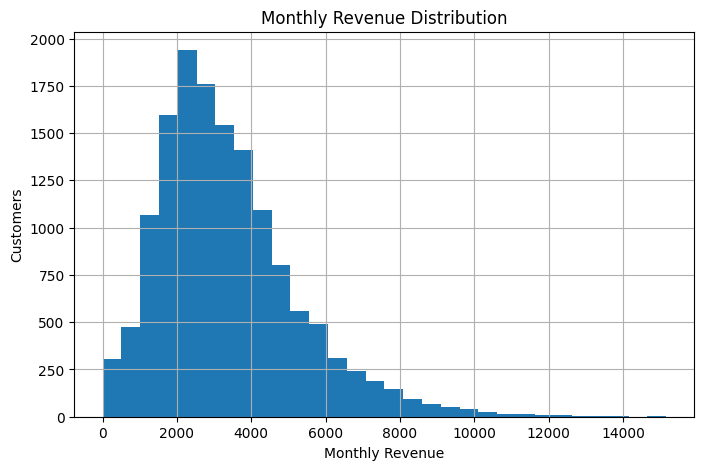

In [0]:
# Histogram

# Monthly Revenue 
plt.figure(figsize=(8,5))

plt.hist(

pdf["MonthlyRevenue"],

bins=30

)

plt.title("Monthly Revenue Distribution")

plt.xlabel("Monthly Revenue")

plt.ylabel("Customers")

plt.grid(True)

plt.show()

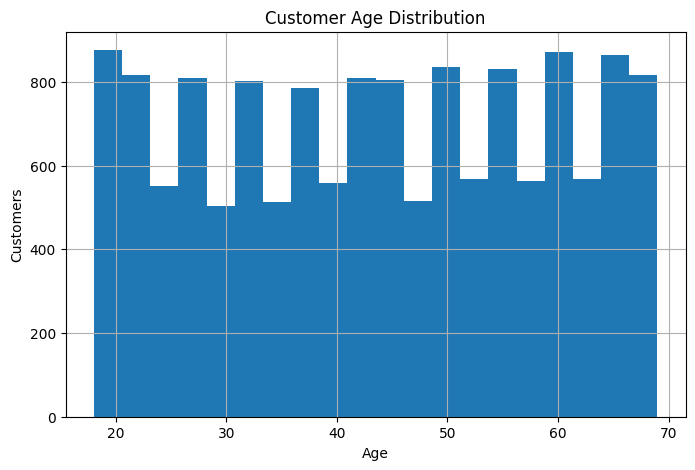

In [0]:
# Histogram
# Age 
plt.figure(figsize=(8,5))

plt.hist(

pdf["Age"],

bins=20

)

plt.title("Customer Age Distribution")

plt.xlabel("Age")

plt.ylabel("Customers")

plt.grid(True)

plt.show()

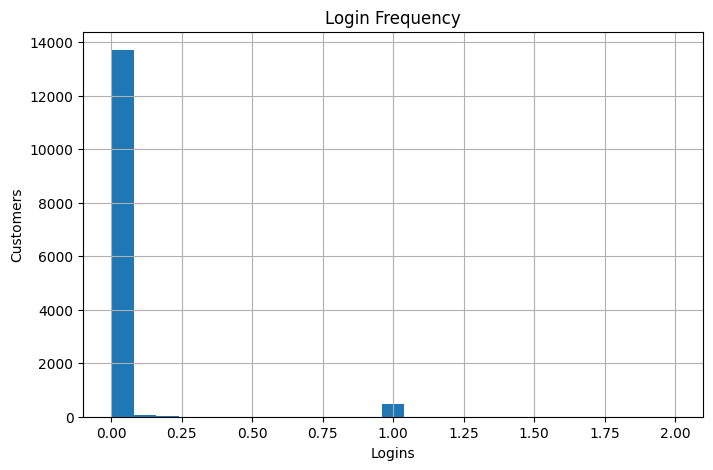

In [0]:
plt.figure(figsize=(8,5))

plt.hist(

pdf["LoginFrequency"],

bins=25

)

plt.title("Login Frequency")

plt.xlabel("Logins")

plt.ylabel("Customers")

plt.grid(True)

plt.show()

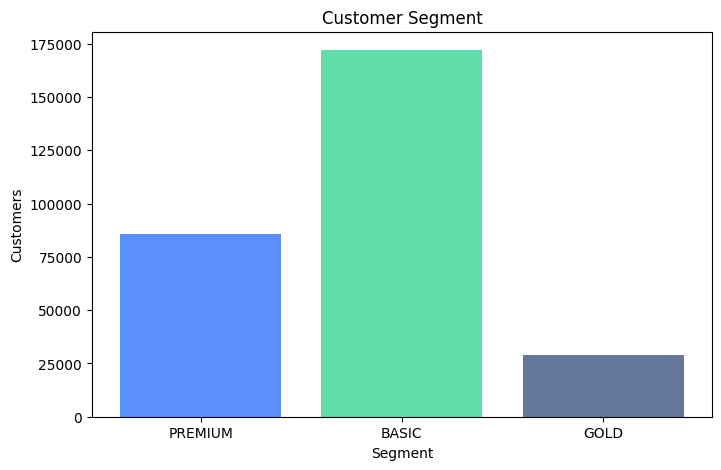

In [0]:
# Bar Chart
# Segment 
segment = gold.groupBy("Segment").count().toPandas()

colors = [
"#5B8FF9",
"#61DDAA",
"#65789B",
"#F6BD16",
"#7262FD"
]

plt.figure(figsize=(8,5))

plt.bar(

segment["Segment"],

segment["count"],

color=colors[:len(segment)]

)

plt.title("Customer Segment")

plt.xlabel("Segment")

plt.ylabel("Customers")

plt.show()

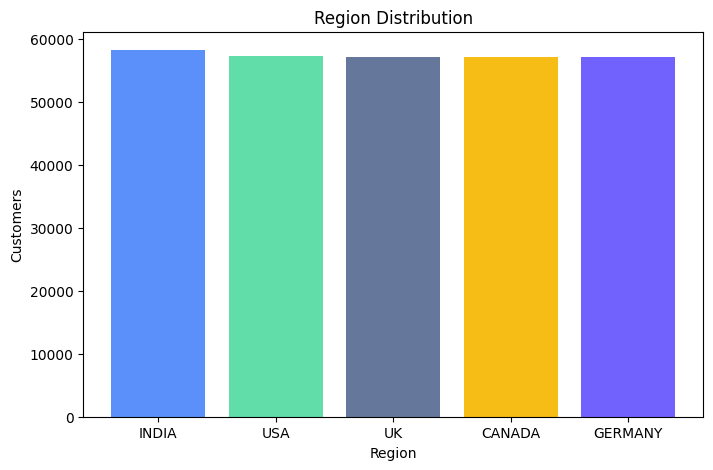

In [0]:
# Bar Chart
# Region 
region = gold.groupBy("Region").count().toPandas()

colors = [
"#5B8FF9",
"#61DDAA",
"#65789B",
"#F6BD16",
"#7262FD",
"#78D3F8"
]

plt.figure(figsize=(8,5))

plt.bar(

region["Region"],

region["count"],

color=colors[:len(region)]

)

plt.title("Region Distribution")

plt.xlabel("Region")

plt.ylabel("Customers")

plt.show()

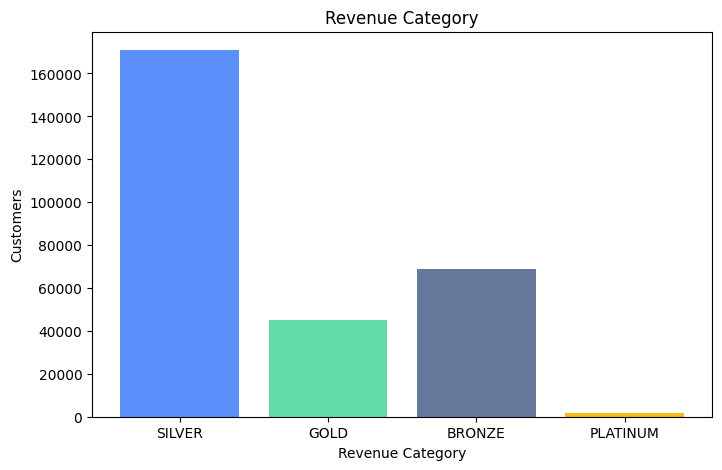

In [0]:
# Bar Chart
# Revenue Category 
rev = gold.groupBy("RevenueCategory").count().toPandas()

colors = [
"#5B8FF9",
"#61DDAA",
"#65789B",
"#F6BD16"
]

plt.figure(figsize=(8,5))

plt.bar(

rev["RevenueCategory"],

rev["count"],

color=colors[:len(rev)]

)

plt.title("Revenue Category")

plt.xlabel("Revenue Category")

plt.ylabel("Customers")

plt.show()

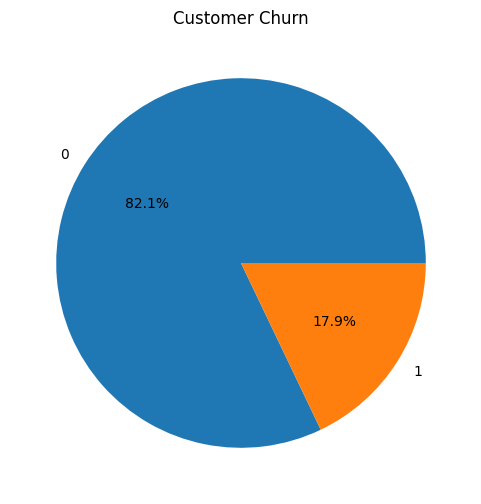

In [0]:
# Pie Chart
# Churn 
churn = gold.groupBy("Churn").count().toPandas()

plt.figure(figsize=(6,6))

plt.pie(

churn["count"],

labels=churn["Churn"],

autopct="%1.1f%%"

)

plt.title("Customer Churn")

plt.show()

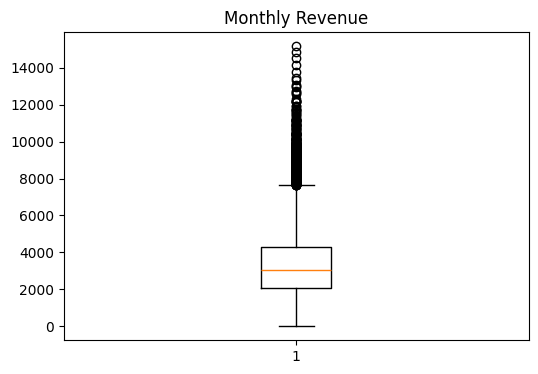

In [0]:
# Box Plot
# Monthly Revenue 
plt.figure(figsize=(6,4))

plt.boxplot(

pdf["MonthlyRevenue"]

)

plt.title("Monthly Revenue")

plt.show()

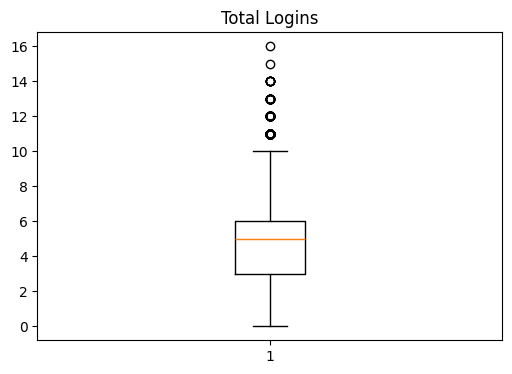

In [0]:
# Box Plot
# Total Logins 
plt.figure(figsize=(6,4))

plt.boxplot(

pdf["TotalLogins"]

)

plt.title("Total Logins")

plt.show()

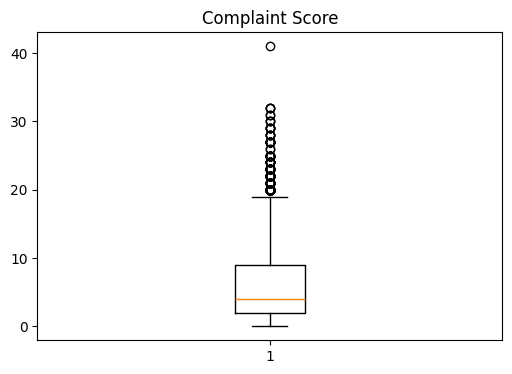

In [0]:
# Box Plot
# Complaint Score 
plt.figure(figsize=(6,4))

plt.boxplot(

pdf["ComplaintScore"]

)

plt.title("Complaint Score")

plt.show()

In [0]:
# Part 1 Summery 
# The objective of Part 1 is to understand the Gold Layer dataset before performing Feature Engineering. We analyze the data structure, data # quality, and customer distribution using statistical summaries and visualizations.

# Step 1 Import Libraries
# Purpose

# Import all the required Python libraries for data analysis and visualization.

# Operations
# Import PySpark functions
# Import Matplotlib
# Import Pandas
# Import NumPy
# Output

# Libraries are loaded successfully.

# Step 2-  Read Gold Dataset
# Purpose

# Load the Gold Layer dataset into Spark.

# Operations
# Read gold_retention_features
# Display sample records
# Output

# Gold dataset is successfully loaded.

# Step 3- Dataset Size
# Purpose

# Understand how large the dataset is.

# Operations
# Count total rows
# Count total columns
# Output

# Example

# Rows : 286893

# Columns : 45

# This tells us how much data will be used for Feature Engineering.

# Step 4 Schema Validation
# Purpose

# Understand the structure of the dataset.

# Operations
# Display column names
# Display data types
# Output

# Shows

# String columns
# Integer columns
# Double columns
# Date columns

# This helps identify categorical and numerical features.

# Step 5 Column Names
# Purpose

# Verify all available features.

# Operations

# Print every column.

# Example

# CustomerID

# Age

# Region

# MonthlyRevenue

# RiskScore

# Step 6 Data Types
# Purpose

# Verify the datatype of every feature.

# Operations

# Display

# Column - Data Type 

# This helps us decide:

# which columns require encoding
# which columns require scaling 

# Step 7  Statistical Summary
# Purpose

# Understand the numerical distribution.

# Operations

# Calculate

# Count
# Mean
# Standard Deviation
# Minimum
# Maximum
# Output

# Statistics for every numerical feature.

# Example

# MonthlyRevenue

# Mean

# Std

# Min

# Max
# Step 8 Churn Distribution
# Purpose

# Understand class balance.

# Operations

# Count

# Churn = 0
# Churn = 1
# Business Insight

# This tells us whether the dataset is balanced or imbalanced.

# Step 9 Customer Segment Analysis
# Purpose

# Analyze customers based on business segments.

# Operations

# Count customers in

# Gold
# Silver
# Platinum
# Business Insight

# Shows which customer segment has the largest customer base.

# Step 10 Region Analysis
# Purpose

# Analyze customer distribution across regions.

# Operations

# Count customers by region.

# Business Insight

# Shows which region contributes the most customers.

# Step 11 Subscription Analysis
# Purpose

# Understand subscription plan distribution.

# Operations

# Count

# Basic
# Premium
# Enterprise
# Business Insight

# Helps identify the most popular subscription plan.

# Step 12  Sample Dataset
# Purpose

# Convert a small sample into Pandas.

# Operations

# Take a 5% sample.

# Why?

# The complete dataset contains nearly 287,000 records. Creating visualizations on the full dataset would consume more memory and take longer # to render. A representative sample provides faster and more efficient visualization while preserving the overall distribution.

# Step 13 Revenue Distribution
# Purpose

# Visualize customer revenue.

# Graph

# Histogram

# Business Insight

# Shows whether revenue is evenly distributed or skewed.

# Step 14 Age Distribution
# Purpose

# Understand customer age groups.

# Graph

# Histogram

# Business Insight

# Identifies the dominant customer age range.

# Step 15 Login Frequency
# Purpose

# Analyze customer engagement.

# Graph

# Histogram

# Business Insight

# Shows how frequently customers log in to the platform.

# Step 16  Customer Segment Chart
# Purpose

# Visualize customer segments.

# Graph

# Bar Chart

# Business Insight

# Compares the number of customers in each business segment.

# Step 17  Region Chart
# Purpose

# Visualize customer distribution by region.

# Graph

# Bar Chart

# Business Insight

# Helps identify high-performing regions.

# Step 18  Revenue Category
# Purpose

# Visualize revenue categories.

# Graph

# Bar Chart

# Business Insight

# Shows the distribution of customers across different revenue levels.

# Step 19  Churn Percentage
# Purpose

# Visualize churn rate.

# Graph

# Pie Chart

# Business Insight

# Shows the percentage of retained versus churned customers.

# Step 20 22  Box Plots
# Purpose

# Detect outliers.

# Graphs
# Monthly Revenue
# Total Logins
# Complaint Score
# Business Insight

# These box plots help identify extreme values that may negatively affect machine learning performance. In the next part of the notebook, # these outliers will be treated using the IQR capping method.

In [0]:
# What We Achieved

# By the end of Part 1, we have:

# Successfully loaded the Gold Layer dataset.
# Verified the dataset structure, size, and schema.
# Explored customer distribution across churn, segment, region, and subscription type.
# Generated descriptive statistics for numerical features.
# Created visualizations (histograms, bar charts, pie chart, and box plots) to understand data distribution.

In [0]:
# In Part 1 of Feature Engineering, I performed exploratory data analysis on the Gold Layer dataset. I validated the schema, analyzed customer demographics, revenue, churn, and engagement patterns using statistical summaries and visualizations. This helped me understand the data and identify issues such as outliers before creating machine learning features."

In [0]:
# Part 2
# Objective

# The objective of Part 2 is to improve the quality of the dataset by:

# Checking missing values
# Detecting outliers
# Treating outliers using the IQR method
# Saving the cleaned dataset

In [0]:
# # Part 2 – Data Cleaning

## Objective

# This section performs data cleaning before feature engineering.

# Operations

# • Missing Value Analysis
# • Outlier Detection
# • Outlier Treatment using IQR
# • Save Clean Dataset

# Output

# gold_outlier_treated

In [0]:
# Check Missing Values
# Purpose

# Check whether any column contains NULL values. 

from pyspark.sql.functions import col, count, when

display(

gold.select([

count(

when(

col(c).isNull(),

c

)

).alias(c)

for c in gold.columns

])

)

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore
0,0,0,0,0,0,0,0,4968,0,0,0,0,0,1870,1870,0,0,1870,1870,0,0,38165,0,0,0,0,38165,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [0]:
# Missing Value Validation 
total_nulls = 0

for c in gold.columns:

    total_nulls += gold.filter(col(c).isNull()).count()

if total_nulls == 0:

    print("PASS - No Missing Values")

else:

    print("Missing Values Found :", total_nulls)

❌ Missing Values Found : 88778


In [0]:
# Numerical Columns for Outlier Detection 
outlier_columns = [

"MonthlyRevenue",

"TransactionCount",

"TotalLogins",

"LifetimeMinutes",

"AvgSession",

"ComplaintScore",

"RiskScore",

"CustomerHealth",

"LoyaltyScore"

]



In [0]:
# Detect Outliers (Before Treatment) 
pdf = gold.select(outlier_columns).sample(False,0.05,42).toPandas()

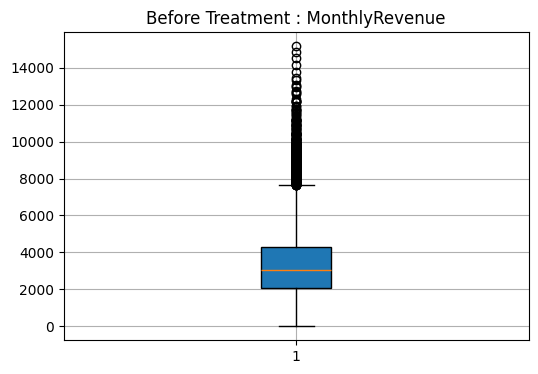

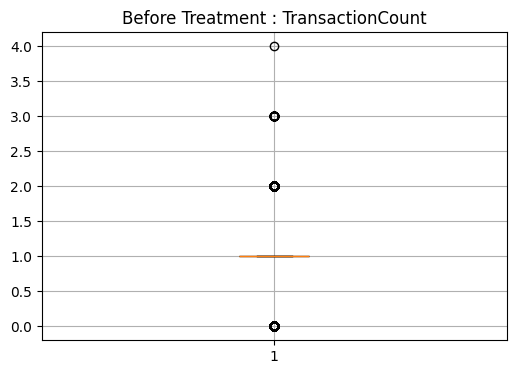

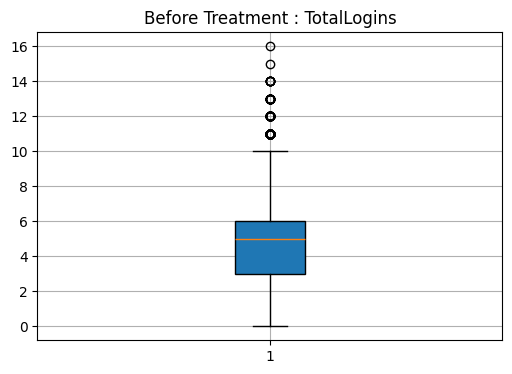

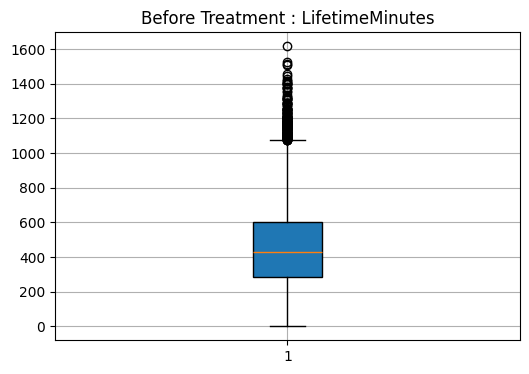

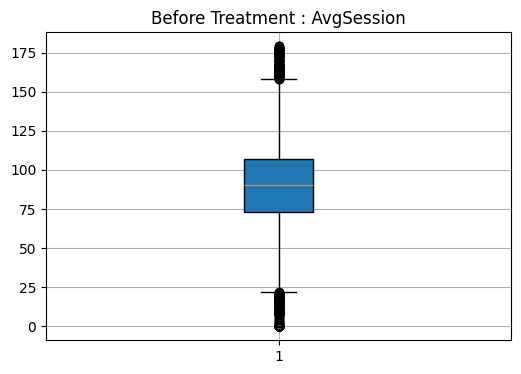

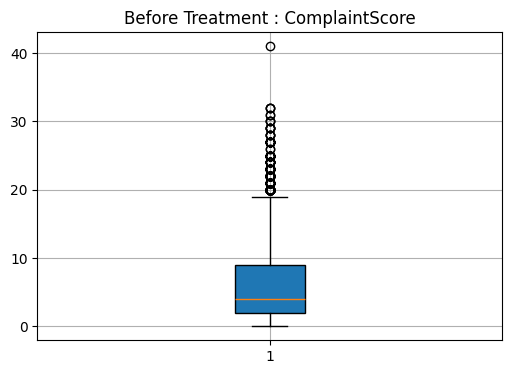

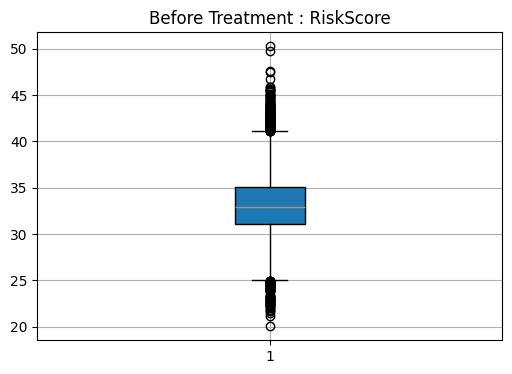

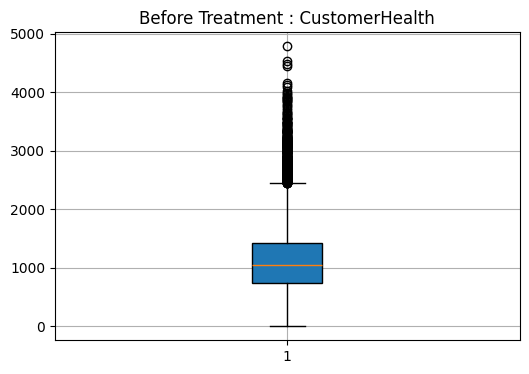

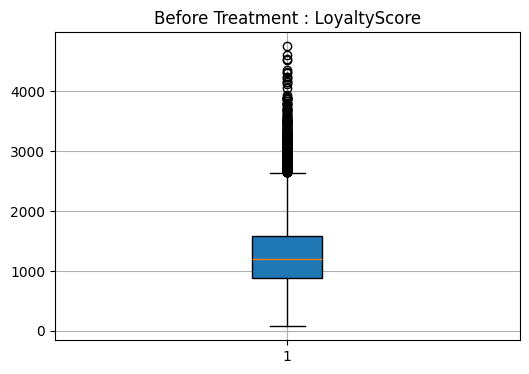

In [0]:
# Box Plots Before Treatment 
import matplotlib.pyplot as plt

for column in outlier_columns:

    plt.figure(figsize=(6,4))

    plt.boxplot(

        pdf[column].dropna(),

        patch_artist=True

    )

    plt.title(f"Before Treatment : {column}")

    plt.grid(True)

    plt.show()

In [0]:
# Here i notice several extreme values (outliers) outside the whiskers of the box plots. These values can negatively affect machine learning models if left untreated.

In [0]:
# Treat Outliers Using IQR Capping 
from pyspark.sql.functions import when

for column in outlier_columns:

    q1, q3 = gold.approxQuantile(

        column,

        [0.25,0.75],

        0

    )

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr

    upper = q3 + 1.5 * iqr

    gold = gold.withColumn(

        column,

        when(col(column) < lower, lower)

        .when(col(column) > upper, upper)

        .otherwise(col(column))

    )

In [0]:
# Verify Outlier Treatment 
pdf_after = gold.select(outlier_columns).sample(False,0.05,42).toPandas()

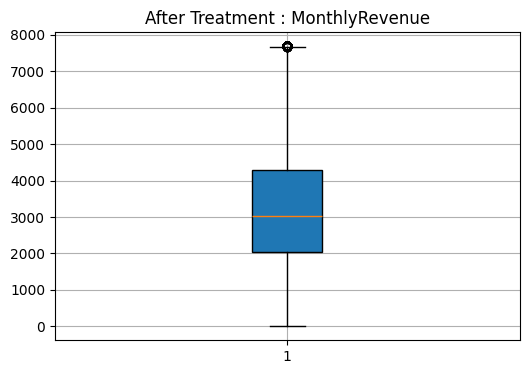

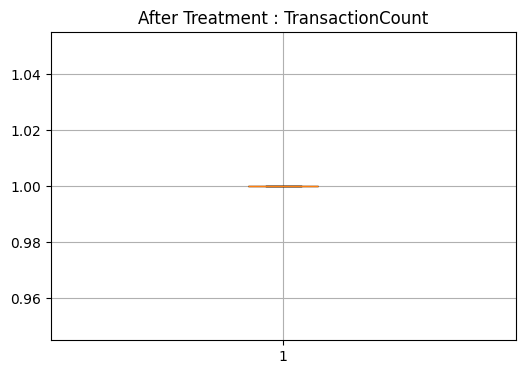

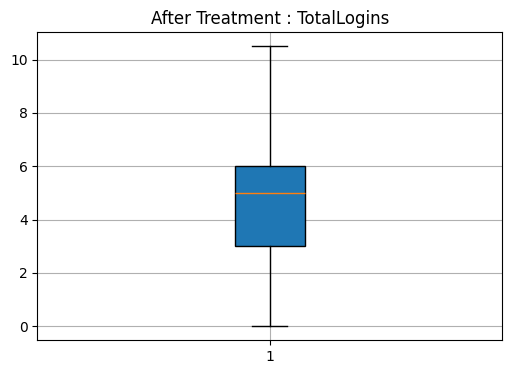

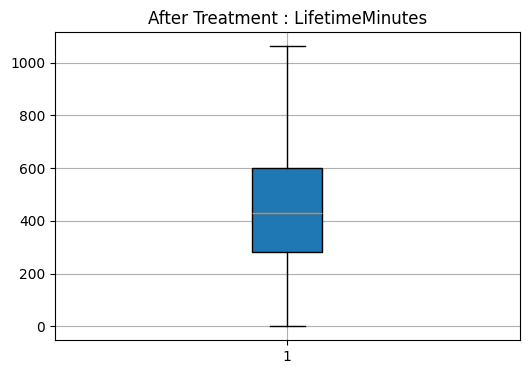

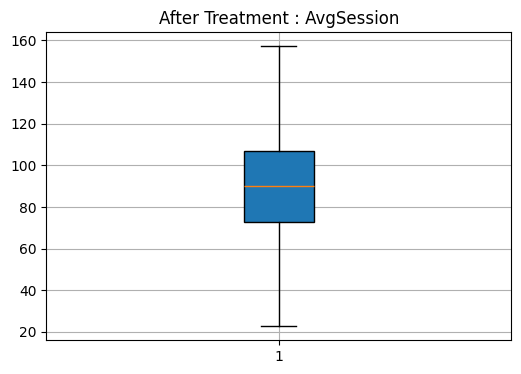

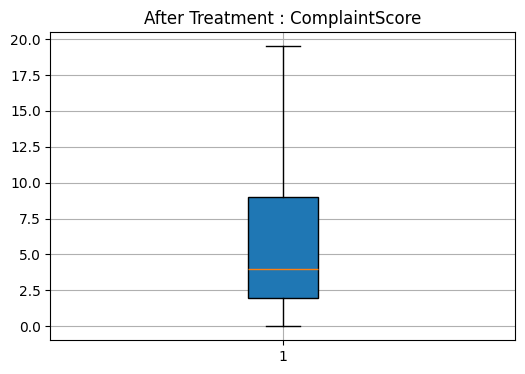

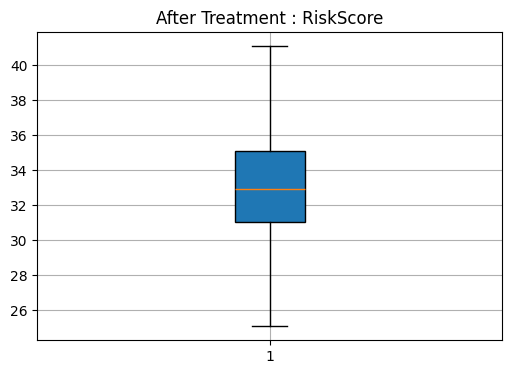

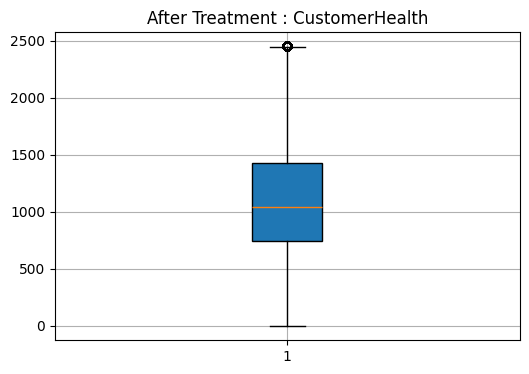

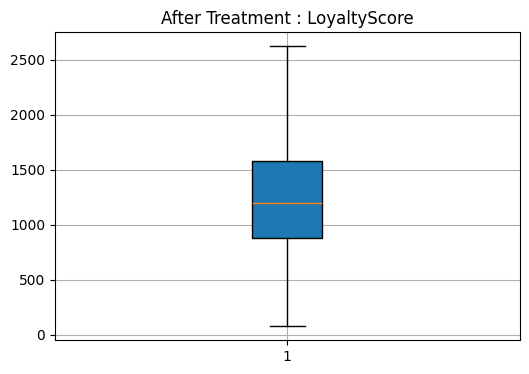

In [0]:
# Box Plots After Treatment 
for column in outlier_columns:

    plt.figure(figsize=(6,4))

    plt.boxplot(

        pdf_after[column].dropna(),

        patch_artist=True

    )

    plt.title(f"After Treatment : {column}")

    plt.grid(True)

    plt.show()

In [0]:
# Observation

# Compared to the earlier box plots:

# Extreme values have been capped.
# The number of outliers is significantly reduced.
# All customer records are preserved because we used IQR capping instead of deleting rows.

In [0]:
# Validate Row Count 
print("Rows after Outlier Treatment :", gold.count())

Rows after Outlier Treatment : 286893


In [0]:
# Save Clean Dataset 
gold.write \
.mode("overwrite") \
.option("overwriteSchema","true") \
.saveAsTable("gold_outlier_treated")

In [0]:
# Verify Saved Table 
display(

spark.table(

"gold_outlier_treated"

).limit(10)

)

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,987.09,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,981.09,EXCELLENT,1147.19
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,1081.12,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1070.12,EXCELLENT,1007.62
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,1258.53,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1252.53,EXCELLENT,1193.23
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,772.28,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,768.28,EXCELLENT,1017.48
100060,2025-01-19,BASIC,CANADA,53,MONTHLY,523,45-59,2025-04,5080.76,1.0,5.0,652.0,130.4,2025-12-03,2024-03-16,627,0.01,LOW,LONG,0,1,2025-08-04,0,1,2.0,LOW,0.0,LOW,0,ACTIVE,1,1016.15,0.2,1721.83,2.0,GOLD,ESTABLISHED,LOW,LIGHT,29.42,0,1719.83,EXCELLENT,1631.33
100068,2020-06-01,BASIC,UK,19,MONTHLY,2216,18-24,2024-08,1825.58,1.0,10.0,762.0,76.2,2025-12-03,2024-02-14,658,0.02,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,182.56,0.2,780.27,2.0,BRONZE,LOYAL,LOW,LIGHT,32.17,0,776.27,EXCELLENT,995.87
100082,2020-11-17,BASIC,CANADA,47,MONTHLY,2047,45-59,2025-10,5793.53,1.0,3.0,433.0,144.33333333333334,2025-12-17,2025-01-15,336,0.01,LOW,LONG,0,0,null,0,0,0.0,LOW,null,LOW,0,ACTIVE,1,1931.18,0.0,1869.16,0.0,GOLD,LOYAL,LOW,LIGHT,28.31,0,1869.16,EXCELLENT,2148.96
100084,2023-06-13,BASIC,UK,61,MONTHLY,1109,60+,2024-03,1674.21,1.0,3.0,281.0,93.66666666666667,2025-03-21,2024-03-06,380,0.01,LOW,LONG,0,2,2024-08-05,1,1,9.0,LOW,0.5,LOW,0,ACTIVE,1,558.07,0.67,587.76,4.5,BRONZE,LOYAL,LOW,LIGHT,36.93,0,578.76,EXCELLENT,725.56
100135,2021-08-30,BASIC,CANADA,60,MONTHLY,1761,60+,2025-06,1854.49,1.0,5.0,247.0,49.4,2025-11-07,2024-07-14,481,0.01,LOW,MEDIUM,0,4,2025-08-24,1,3,13.0,LOW,0.25,LOW,0,ACTIVE,1,370.9,0.8,632.45,3.25,BRONZE,LOYAL,LOW,LIGHT,38.15,0,619.45,EXCELLENT,911.05
100140,2025-05-19,BASIC,CANADA,18,MONTHLY,403,18-24,2024-12,1880.07,1.0,5.0,363.0,72.6,2025-11-28,2024-08-28,457,0.01,LOW,LONG,0,2,2024-04-02,1,1,9.0,LOW,0.5,LOW,1,CHURNED,0,376.01,0.4,674.92,4.5,BRONZE,ESTABLISHED,LOW,LIGHT,36.12,0,665.92,EXCELLENT,647.12


In [0]:
# Part 2 Summary 
# In this section, the Gold Layer dataset was cleaned to improve its quality before feature engineering.

# The following operations were completed:

# • Checked for missing values across all columns.
# • Verified that the dataset contained no NULL values.
# • Identified outliers in important numerical features using box plots.
# • Applied IQR-based capping (Winsorization) to reduce the influence of extreme values.
# • Preserved all customer records by capping values instead of deleting rows.
# • Saved the cleaned dataset as `gold_outlier_treated` for further feature engineering.

In [0]:
# "Before creating machine learning features, I performed data quality checks on the Gold Layer dataset. I verified that there were no missing values and detected outliers using box plots and the Interquartile Range (IQR) method. Instead of removing records, I applied IQR-based capping (Winsorization) to limit extreme values while preserving all customer records. The cleaned dataset was then saved as gold_outlier_treated for subsequent feature engineering."

In [0]:
# Part 3
# Objective

# The objective of Part 3 is to prepare the cleaned dataset for Machine Learning by:

# Creating new business features
# Encoding categorical variables
# Scaling numerical variables
# Creating the ML feature vector
# Saving the ML-ready dataset
# Markdown Cell

# Part 3 – Feature Engineering
# This section prepares the cleaned Gold dataset for Machine Learning.

# Operations

# • Read Clean Dataset
# • Create New Features
# • Encode Categorical Variables
# • Feature Scaling
# • Create ML Feature Vector
# • Save Scaled Dataset

# Output

# gold_scaled_features

In [0]:
# Read Clean Dataset 
gold = spark.table("gold_outlier_treated")
display(gold.limit(5)) 


CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,987.09,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,981.09,EXCELLENT,1147.19
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,1081.12,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1070.12,EXCELLENT,1007.62
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,1258.53,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1252.53,EXCELLENT,1193.23
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,772.28,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,768.28,EXCELLENT,1017.48
100060,2025-01-19,BASIC,CANADA,53,MONTHLY,523,45-59,2025-04,5080.76,1.0,5.0,652.0,130.4,2025-12-03,2024-03-16,627,0.01,LOW,LONG,0,1,2025-08-04,0,1,2.0,LOW,0.0,LOW,0,ACTIVE,1,1016.15,0.2,1721.83,2.0,GOLD,ESTABLISHED,LOW,LIGHT,29.42,0,1719.83,EXCELLENT,1631.33


In [0]:
#Verify Dataset 
print("Rows :", gold.count())

print("Columns :", len(gold.columns))

Rows : 286893
Columns : 45


In [0]:
from pyspark.sql.functions import col, round

In [0]:
# Revenue Per Day 
from pyspark.sql.functions import col, round, when

gold = gold.withColumn(
    "RevenuePerDay",
    when(
        col("TenureDays") > 0,
        round(col("MonthlyRevenue") / col("TenureDays"), 2)
    ).otherwise(0)
)

In [0]:
# Revenue Per Login 
gold = gold.withColumn(
    "RevenuePerLogin",
    when(
        col("TotalLogins") > 0,
        round(col("MonthlyRevenue") / col("TotalLogins"), 2)
    ).otherwise(0)
)

In [0]:
# Tickets Per Login 
gold = gold.withColumn(
    "TicketsPerLogin",
    when(
        col("TotalLogins") > 0,
        round(col("TotalTickets") / col("TotalLogins"), 2)
    ).otherwise(0)
)

In [0]:
# Complaint Ratio 
gold = gold.withColumn(
    "ComplaintRatio",
    when(
        col("TotalTickets") > 0,
        round(col("ComplaintScore") / col("TotalTickets"), 2)
    ).otherwise(0)
)

In [0]:
# Engagement Score 
gold = gold.withColumn(
    "EngagementScore",
    round(
        (
            col("LoginFrequency") +
            col("AvgSession") +
            col("ActiveDays")
        ) / 3,
        2
    )
)

In [0]:
# Customer Health 
gold = gold.withColumn(
    "CustomerHealth",
    round(
        (
            col("EngagementScore") +
            col("MonthlyRevenue")
        ) / 2,
        2
    )
)

In [0]:
# Loyalty Score 
gold = gold.withColumn(
    "LoyaltyScore",
    round(
        (
            col("TenureDays") +
            col("TransactionCount")
        ) / 2,
        2
    )
)

In [0]:
# Verify Features 
display(
    gold.select(
        "RevenuePerDay",
        "RevenuePerLogin",
        "TicketsPerLogin",
        "ComplaintRatio",
        "EngagementScore",
        "CustomerHealth",
        "LoyaltyScore"
    )
)

RevenuePerDay,RevenuePerLogin,TicketsPerLogin,ComplaintRatio,EngagementScore,CustomerHealth,LoyaltyScore
1.93,472.55,0.5,2.0,175.5,1505.4,734.5
4.47,416.06,0.43,3.67,170.82,1541.61,326.5
3.43,414.93,0.38,2.0,226.05,1772.74,484.0
1.37,569.73,0.5,2.0,149.84,1214.39,830.0
9.71,1016.15,0.2,2.0,252.47,2666.62,262.0
0.82,182.56,0.2,2.0,244.74,1035.16,1108.5
2.83,1931.18,0.0,0.0,160.11,2976.82,1024.0
1.51,558.07,0.67,4.5,157.89,916.05,555.0
1.05,370.9,0.8,3.25,176.8,1015.65,881.0
4.67,376.01,0.4,4.5,176.54,1028.31,202.0


In [0]:
# Save Feature Engineered Dataset
# Purpose

# Save the newly created features before encoding.  

gold.write \
.mode("overwrite") \
.option("overwriteSchema","true") \
.saveAsTable("gold_feature_engineered")

In [0]:
# Read Feature Engineered Dataset 
gold = spark.table("gold_feature_engineered")

display(gold.limit(5))

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore,RevenuePerDay
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,175.5,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,1505.4,EXCELLENT,734.5,1.93
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,170.82,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1541.61,EXCELLENT,326.5,4.47
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,226.05,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1772.74,EXCELLENT,484.0,3.43
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,149.84,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,1214.39,EXCELLENT,830.0,1.37
100060,2025-01-19,BASIC,CANADA,53,MONTHLY,523,45-59,2025-04,5080.76,1.0,5.0,652.0,130.4,2025-12-03,2024-03-16,627,0.01,LOW,LONG,0,1,2025-08-04,0,1,2.0,LOW,0.0,LOW,0,ACTIVE,1,1016.15,0.2,252.47,2.0,GOLD,ESTABLISHED,LOW,LIGHT,29.42,0,2666.62,EXCELLENT,262.0,9.71


In [0]:
# Import ML Libraries 
from pyspark.ml.feature import StringIndexer
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.feature import StandardScaler

In [0]:
# Define Categorical Columns 
categorical_columns = [

    "Segment",

    "Region",

    "SubscriptionType",

    "RevenueCategory",

    "UsageCategory",

    "SupportRisk"

]

In [0]:
# Encode Categorical Columns 
for column in categorical_columns:

    indexer = StringIndexer(

        inputCol=column,

        outputCol=column + "_Index",

        handleInvalid="keep"

    )

    model = indexer.fit(gold)

    gold = model.transform(gold)

In [0]:
# Verify Encoded Columns 
display(

gold.select(

"Segment",

"Segment_Index",

"Region",

"Region_Index",

"SubscriptionType",

"SubscriptionType_Index"

)

)

Segment,Segment_Index,Region,Region_Index,SubscriptionType,SubscriptionType_Index
PREMIUM,1.0,INDIA,0.0,MONTHLY,0.0
BASIC,0.0,USA,1.0,MONTHLY,0.0
BASIC,0.0,UK,2.0,MONTHLY,0.0
BASIC,0.0,USA,1.0,MONTHLY,0.0
BASIC,0.0,CANADA,3.0,MONTHLY,0.0
BASIC,0.0,UK,2.0,MONTHLY,0.0
BASIC,0.0,CANADA,3.0,MONTHLY,0.0
BASIC,0.0,UK,2.0,MONTHLY,0.0
BASIC,0.0,CANADA,3.0,MONTHLY,0.0
BASIC,0.0,CANADA,3.0,MONTHLY,0.0


In [0]:
# Select Numerical Features 
numeric_features = [

"Age",

"TenureDays",

"MonthlyRevenue",

"TransactionCount",

"TotalLogins",

"LifetimeMinutes",

"AvgSession",

"ActiveDays",

"LoginFrequency",

"TotalTickets",

"ComplaintScore",

"RevenuePerDay",

"RevenuePerLogin",

"TicketsPerLogin",

"ComplaintRatio",

"EngagementScore",

"CustomerHealth",

"LoyaltyScore"

]

In [0]:
# Select Numerical Features 
numeric_features = [

"Age",

"TenureDays",

"MonthlyRevenue",

"TransactionCount",

"TotalLogins",

"LifetimeMinutes",

"AvgSession",

"ActiveDays",

"LoginFrequency",

"TotalTickets",

"ComplaintScore",

"RevenuePerDay",

"RevenuePerLogin",

"TicketsPerLogin",

"ComplaintRatio",

"EngagementScore",

"CustomerHealth",

"LoyaltyScore"

]

In [0]:
# Create Feature Vector 
assembler = VectorAssembler(

    inputCols=numeric_features,

    outputCol="features",

    handleInvalid="keep"

)

gold = assembler.transform(gold)

In [0]:
# Scale Numerical Features 

scaler = StandardScaler(

    inputCol="features",

    outputCol="scaled_features",

    withStd=True,

    withMean=True

)

scaler_model = scaler.fit(gold)

gold = scaler_model.transform(gold)


In [0]:

# Verify Feature Vector
# Purpose

# Verify that the VectorAssembler and StandardScaler have successfully created the feature vectors.

# This confirms that the dataset is now ready for Machine Learning.
display(
    gold.select(
        "features",
        "scaled_features"
    )
)

features,scaled_features
"{""type"":""1"",""size"":null,""indices"":null,""values"":[""48.0"",""1468.0"",""2835.29"",""1.0"",""6.0"",""447.0"",""74.5"",""452.0"",""0.01"",""3.0"",""6.0"",""1.93"",""472.55"",""0.5"",""2.0"",""175.5"",""1505.4"",""734.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}"
"{""type"":""1"",""size"":null,""indices"":null,""values"":[""43.0"",""652.0"",""2912.39"",""1.0"",""7.0"",""682.0"",""97.42857142857143"",""415.0"",""0.02"",""3.0"",""11.0"",""4.47"",""416.06"",""0.43"",""3.67"",""170.82"",""1541.61"",""326.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}"
"{""type"":""1"",""size"":null,""indices"":null,""values"":[""55.0"",""967.0"",""3319.43"",""1.0"",""8.0"",""865.0"",""108.125"",""570.0"",""0.01"",""3.0"",""6.0"",""3.43"",""414.93"",""0.38"",""2.0"",""226.05"",""1772.74"",""484.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}"
"{""type"":""1"",""size"":null,""indices"":null,""values"":[""35.0"",""1659.0"",""2278.93"",""1.0"",""4.0"",""290.0"",""72.5"",""377.0"",""0.01"",""2.0"",""4.0"",""1.37"",""569.73"",""0.5"",""2.0"",""149.84"",""1214.39"",""830.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.5714469091134694"",""0.5017037789362383"",""-0.5912320345914457"",""0.0"",""-0.4484382496396012"",""-0.6976644474584527"",""-0.6542564223713676"",""-0.3646982166904183"",""-0.20528502621170325"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.6653263340107006"",""-0.35087869992540816"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.4510289960825741"",""-0.6070927175107699"",""0.5017037789362383""]}"
"{""type"":""1"",""size"":null,""indices"":null,""values"":[""53.0"",""523.0"",""5080.76"",""1.0"",""5.0"",""652.0"",""130.4"",""627.0"",""0.01"",""1.0"",""2.0"",""9.71"",""1016.15"",""0.2"",""2.0"",""252.47"",""2666.62"",""262.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6270066423868055"",""-1.4665176541698055"",""1.0250281728877428"",""0.0"",""0.008208379665322391"",""0.8888830904649767"",""1.546248748766258"",""0.9874235260366689"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""2.5985000807153225"",""0.21640979219593814"",""-0.5681575624813238"",""-0.34133703226515455"",""1.1890099280292505"",""1.0672193128192116"",""-1.4665176541698055""]}"
"{""type"":""1"",""size"":null,""indices"":null,""values"":[""19.0"",""2216.0"",""1825.58"",""1.0"",""10.0"",""762.0"",""76.2"",""658.0"",""0.02"",""2.0"",""4.0"",""0.82"",""182.56"",""0.2"",""2.0"",""244.74"",""1035.16"",""1108.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-1.6367389548914917"",""1.466756013302494"",""-0.8527509579596336"",""0.0"",""2.2914415261899403"",""1.3

In [0]:
# Verify Schema 
gold.printSchema()

root
 |-- CustomerID: long (nullable = true)
 |-- JoinDate: date (nullable = true)
 |-- Segment: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Age: long (nullable = true)
 |-- SubscriptionType: string (nullable = true)
 |-- TenureDays: integer (nullable = true)
 |-- AgeGroup: string (nullable = true)
 |-- BillingMonth: string (nullable = true)
 |-- MonthlyRevenue: double (nullable = true)
 |-- TransactionCount: double (nullable = true)
 |-- TotalLogins: double (nullable = true)
 |-- LifetimeMinutes: double (nullable = true)
 |-- AvgSession: double (nullable = true)
 |-- LastLoginDate: date (nullable = true)
 |-- FirstLoginDate: date (nullable = true)
 |-- ActiveDays: integer (nullable = true)
 |-- LoginFrequency: double (nullable = true)
 |-- UsageLevel: string (nullable = true)
 |-- SessionCategory: string (nullable = true)
 |-- RecentlyActive: integer (nullable = true)
 |-- TotalTickets: long (nullable = true)
 |-- LastTicketDate: date (nullable = true)
 |-- Ope

In [0]:
# Verify Number of Records 

print("Total Records :", gold.count())

Total Records : 286893


In [0]:
# Verify Number of Columns 
print("Total Columns :", len(gold.columns))

Total Columns : 54


In [0]:
# Verify Null Values in Feature Vectors 
from pyspark.sql.functions import col

display(
    gold.select(
        col("features"),
        col("scaled_features")
    )
    .filter(
        col("features").isNull() |
        col("scaled_features").isNull()
    )
)

features,scaled_features


In [0]:
# Expected Output:

# No rows returned. This confirms that all records have valid feature vectors.  

# Machine learning algorithms in Spark ML expect the input variables to be combined into a single vector. I used VectorAssembler to combine # all numerical features into the features column. Then I applied StandardScaler to standardize the values, creating scaled_features, which # improves model performance by ensuring that all numerical features are on a comparable scale."


In [0]:
# Save Scaled Dataset 
(
    gold.write
        .mode("overwrite")
        .option("overwriteSchema", "true")
        .saveAsTable("gold_scaled_features")
)


In [0]:
# Verify Saved Table 
gold_scaled = spark.table("gold_scaled_features")

print("Total Rows :", gold_scaled.count())

print("Total Columns :", len(gold_scaled.columns))

display(gold_scaled.limit(10))

Total Rows : 286893
Total Columns : 54


CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore,RevenuePerDay,Segment_Index,Region_Index,SubscriptionType_Index,RevenueCategory_Index,UsageCategory_Index,SupportRisk_Index,features,scaled_features
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,175.5,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,1505.4,EXCELLENT,734.5,1.93,1.0,0.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""48.0"",""1468.0"",""2835.29"",""1.0"",""6.0"",""447.0"",""74.5"",""452.0"",""0.01"",""3.0"",""6.0"",""1.93"",""472.55"",""0.5"",""2.0"",""175.5"",""1505.4"",""734.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}"
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,170.82,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1541.61,EXCELLENT,326.5,4.47,0.0,1.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""43.0"",""652.0"",""2912.39"",""1.0"",""7.0"",""682.0"",""97.42857142857143"",""415.0"",""0.02"",""3.0"",""11.0"",""4.47"",""416.06"",""0.43"",""3.67"",""170.82"",""1541.61"",""326.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}"
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,226.05,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1772.74,EXCELLENT,484.0,3.43,0.0,2.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""55.0"",""967.0"",""3319.43"",""1.0"",""8.0"",""865.0"",""108.125"",""570.0"",""0.01"",""3.0"",""6.0"",""3.43"",""414.93"",""0.38"",""2.0"",""226.05"",""1772.74"",""484.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}"
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,149.84,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,1214.39,EXCELLENT,830.0,1.37,0

In [0]:
display(
    spark.table("gold_scaled_features").limit(5)
)

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore,RevenuePerDay,Segment_Index,Region_Index,SubscriptionType_Index,RevenueCategory_Index,UsageCategory_Index,SupportRisk_Index,features,scaled_features
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,175.5,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,1505.4,EXCELLENT,734.5,1.93,1.0,0.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""48.0"",""1468.0"",""2835.29"",""1.0"",""6.0"",""447.0"",""74.5"",""452.0"",""0.01"",""3.0"",""6.0"",""1.93"",""472.55"",""0.5"",""2.0"",""175.5"",""1505.4"",""734.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}"
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,170.82,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1541.61,EXCELLENT,326.5,4.47,0.0,1.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""43.0"",""652.0"",""2912.39"",""1.0"",""7.0"",""682.0"",""97.42857142857143"",""415.0"",""0.02"",""3.0"",""11.0"",""4.47"",""416.06"",""0.43"",""3.67"",""170.82"",""1541.61"",""326.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}"
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,226.05,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1772.74,EXCELLENT,484.0,3.43,0.0,2.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""55.0"",""967.0"",""3319.43"",""1.0"",""8.0"",""865.0"",""108.125"",""570.0"",""0.01"",""3.0"",""6.0"",""3.43"",""414.93"",""0.38"",""2.0"",""226.05"",""1772.74"",""484.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}"
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,149.84,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,1214.39,EXCELLENT,830.0,1.37,0

In [0]:
# Part 4
# Objective

# In this part we will:

# Analyze feature correlation
# Remove redundant features
# Train a temporary Random Forest model
# Calculate feature importance
# Select the best features for Machine Learning

# This is the part interviewers ask about most often.



In [0]:
# Read the Scaled Dataset
# Purpose

# Read the Machine Learning-ready dataset created in Part 3. 
gold = spark.table("gold_scaled_features")

display(gold.limit(5))

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore,RevenuePerDay,Segment_Index,Region_Index,SubscriptionType_Index,RevenueCategory_Index,UsageCategory_Index,SupportRisk_Index,features,scaled_features
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,175.5,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,1505.4,EXCELLENT,734.5,1.93,1.0,0.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""48.0"",""1468.0"",""2835.29"",""1.0"",""6.0"",""447.0"",""74.5"",""452.0"",""0.01"",""3.0"",""6.0"",""1.93"",""472.55"",""0.5"",""2.0"",""175.5"",""1505.4"",""734.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}"
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,170.82,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1541.61,EXCELLENT,326.5,4.47,0.0,1.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""43.0"",""652.0"",""2912.39"",""1.0"",""7.0"",""682.0"",""97.42857142857143"",""415.0"",""0.02"",""3.0"",""11.0"",""4.47"",""416.06"",""0.43"",""3.67"",""170.82"",""1541.61"",""326.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}"
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,226.05,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1772.74,EXCELLENT,484.0,3.43,0.0,2.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""55.0"",""967.0"",""3319.43"",""1.0"",""8.0"",""865.0"",""108.125"",""570.0"",""0.01"",""3.0"",""6.0"",""3.43"",""414.93"",""0.38"",""2.0"",""226.05"",""1772.74"",""484.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}"
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,149.84,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,1214.39,EXCELLENT,830.0,1.37,0

In [0]:
# Verify Dataset 
print("Rows :", gold.count())

print("Columns :", len(gold.columns))

Rows : 286893
Columns : 54


In [0]:
# Import Libraries 
import pandas as pd

import matplotlib.pyplot as plt

In [0]:
# Select Numerical Features 
numeric_columns = [

"Age",

"TenureDays",

"MonthlyRevenue",

"TransactionCount",

"TotalLogins",

"LifetimeMinutes",

"AvgSession",

"ActiveDays",

"LoginFrequency",

"TotalTickets",

"ComplaintScore",

"RevenuePerDay",

"RevenuePerLogin",

"TicketsPerLogin",

"ComplaintRatio",

"EngagementScore",

"CustomerHealth",

"LoyaltyScore"

]

In [0]:
# Convert to Pandas

# We only need these columns for correlation.  
corr_df = gold.select(

numeric_columns

).toPandas()

In [0]:
# Correlation Matrix 
corr_matrix = corr_df.corr()

display(corr_matrix)

Age,TenureDays,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,ActiveDays,LoginFrequency,TotalTickets,ComplaintScore,RevenuePerDay,RevenuePerLogin,TicketsPerLogin,ComplaintRatio,EngagementScore,CustomerHealth,LoyaltyScore
1.0,0.0032085431539542043,-9.489448970749666E-4,null,0.0012137319525352083,-2.812588885578222E-4,4.8766914365240636E-4,2.334409920578016E-4,-0.006758928725331663,-5.517172598531956E-4,0.0011698944189502303,-0.0019593578913223823,-0.004144762761869181,-0.003820783919532408,0.0026953024786358906,2.918445246346233E-4,-9.377604930873258E-4,0.0032085431539542043
0.0032085431539542043,1.0,0.0029047033285240784,null,-0.0014722644648625044,-0.003941811788853972,-0.002051150095987416,0.0032930811789689774,-0.006096664792796898,0.001532005617528448,1.092384653707216E-4,-0.6105318178850204,-7.859586810753513E-4,-0.004421643336069296,-0.0017989861002994734,0.002949851445792298,0.003009123324419614,1.0
-9.489448970749666E-4,0.0029047033285240784,1.0,null,-7.561884983551292E-5,-3.007664482809806E-4,9.951079088699775E-5,0.001005858732470681,-0.0013485337836138468,0.001972274734137914,0.00132004194036549,0.6309720187462116,0.5633543193167492,-6.639111652323072E-4,-3.706205751670269E-4,0.0010031972957762236,0.9993491320798278,0.002904703328524082
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
0.0012137319525352083,-0.0014722644648625044,-7.561884983551292E-5,null,1.0,0.8667344548595814,0.03986817300000661,0.6218654021330482,-0.3378046074064426,0.0020665419744868288,0.0030351384557992197,0.0011090415819493063,-0.5409655844974544,-0.46609046395327103,0.003184752579364882,0.6177233254918272,0.02220797442520974,-0.0014722644648625103
-2.812588885578222E-4,-0.003941811788853972,-3.007664482809806E-4,null,0.8667344548595814,1.0,0.46939614361612814,0.5388316384295756,-0.2911248268800231,0.0027753100390111455,0.004088753569545037,0.0022617608529415857,-0.46803805199117315,-0.403094498635361,0.003843298419690047,0.5961913954303296,0.021206249268085287,-0.003941811788853974
4.8766914365240636E-4,-0.002051150095987416,9.951079088699775E-5,null,0.03986817300000661,0.46939614361612814,1.0,0.040833079736068964,0.013980725367574177,0.0027691730906174604,0.002022392662175918,4.4071169491857715E-4,0.021160470810604015,0.016458877637043793,0.002376716930135499,0.18038613592145694,0.00660664403375387,-0.0020511500959874197
2.334409920578016E-4,0.0032930811789689774,0.001005858732470681,null,0.6218654021330482,0.5388316384295756,0.040833079736068964,1.0,-0.47563655046932224,0.005449745445309902,0.005634951310236942,-0.0012960717946880157,-0.4618114354681878,-0.3963302094603295,1.3810675456305186E-4,0.9901408864750552,0.03672323568549944,0.0032930811789689874
-0.006758928725331663,-0.006096664792796898,-0.0013485337836138468,null,-0.3378046074064426,-0.2911248268800231,0.013980725367574177,-0.47563655046932224,1.0,-0.005473814322900236,-0.004535057829177976,0.002350134884794744,0.5703140281654195,0.48353450979403145,0.003526619965599232,-0.46551367240682207,-0.018140416376756445,-0.0060966647927969
-5.517172598531956E-4,0.001532005617528448,0.001972274734137914,null,0.0020665419744868288,0.0027753100390111455,0.0027691730906174604,0.005449745445309902,-0.005473814322900236,1.0,0.8326932955757562,0.0013516159807792447,-0.0023898307225834374,0.647925226449525,0.31302940913322896,0.005750157612956635,0.00217835158446271,0.0015320056175284567


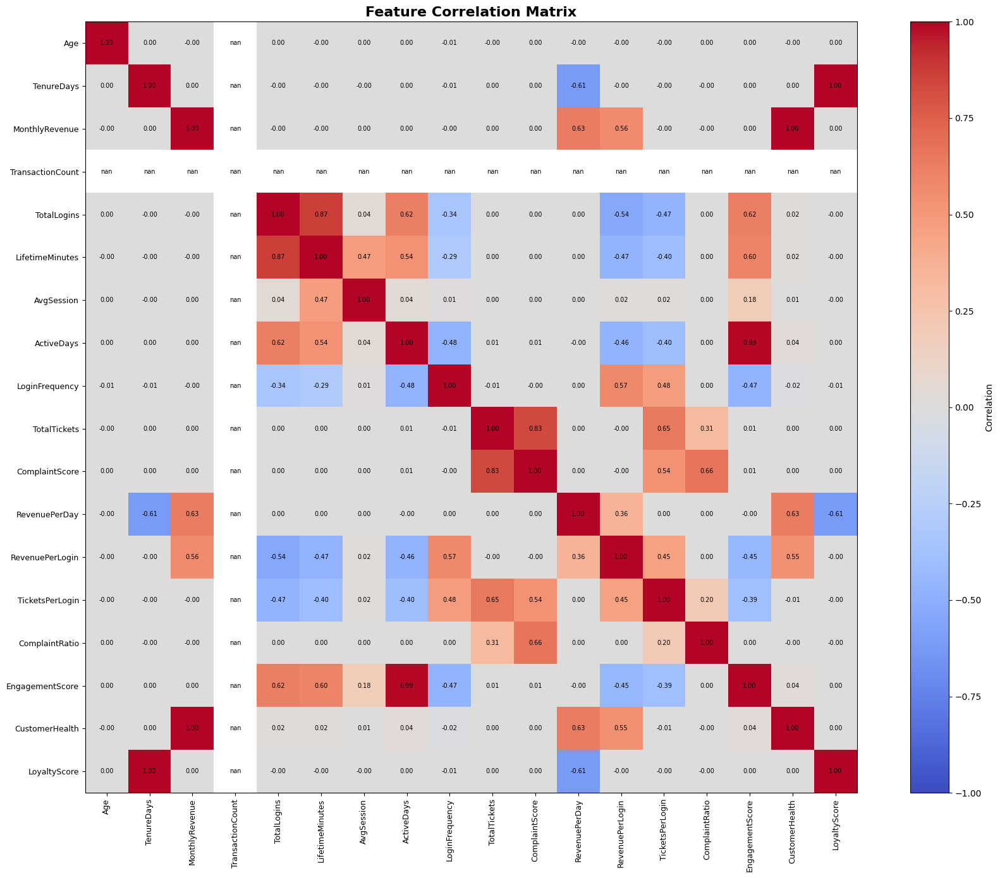

In [0]:
# Correlation Heatmap

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(18,14))

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    np.arange(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90,
    fontsize=9
)

plt.yticks(
    np.arange(len(corr_matrix.columns)),
    corr_matrix.columns,
    fontsize=9
)

# Display correlation value inside each cell
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):

        value = corr_matrix.iloc[i, j]

        plt.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=7
        )

plt.title(
    "Feature Correlation Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

In [0]:
# Objective

# The purpose of the correlation matrix is to measure the strength and direction of the linear relationship between numerical features in the # customer retention dataset before machine learning model training.

# The Pearson correlation coefficient ranges from -1 to +1, where: 
# Understanding the Colours
# heatmap uses three main colours.
# Red:Represents positive correlation.
# When one variable increases, the other variable also increases. 

# Blue: Represents negative correlation.
# When one variable increases, the other variable decreases. 

# White / Grey

# Represents almost no relationship.

# The variables are nearly independent.
# Correlation ≈ 0

# Detailed Interpretation of Results

# Let's interpret the important relationships.

# 1. MonthlyRevenue vs CustomerHealth

# Correlation = 1.00

# Interpretation

# There is a perfect positive correlation between Monthly Revenue and Customer Health.

# This indicates that customers generating higher monthly revenue tend to have better overall customer health scores.

# Business Meaning

# High-value customers generally show stronger engagement and contribute more revenue.

# 2. ActiveDays vs EngagementScore

# Correlation = 0.99

# Interpretation

# This is an extremely strong positive relationship.

# Business Meaning: Customers who remain active for more days have significantly higher engagement scores.

# This validates that EngagementScore is a meaningful engineered feature.

# 3. TotalLogins vs LifetimeMinutes

# Correlation= 0.87

# Interpretation: Customers who log in more frequently generally spend more time using the platform.

# Business Meaning: Higher login frequency indicates greater platform usage.

# 4. TotalTickets vs ComplaintScore

# Correlation= 0.83

# Interpretation: Customers who raise more support tickets generally have higher complaint scores.

# Business Meaning: Frequent support interactions may indicate dissatisfaction and increase churn risk.

# 5. RevenuePerLogin vs MonthlyRevenue

# Correlation = 0.56

# Interpretation: Moderate positive relationship.

# Business Meaning: Customers spending more money generally generate higher revenue per login session.

# 6. ComplaintScore vs ComplaintRatio

# Correlation= 0.66

# Interpretation: Strong positive relationship.

# Business Meaning: Customers with higher complaint scores naturally have higher complaint ratios.

# 7. LoginFrequency vs RevenuePerLogin

# Correlation= 0.57

# Interpretation: Moderate positive correlation.

# Business Meaning: Frequent users generally generate more revenue during their login sessions.

# 8. RevenuePerDay vs TenureDays

# Correlation: -0.61

# Interpretation: Moderately negative relationship.

# Business Meaning: Customers with longer tenure tend to have lower average daily revenue because revenue is distributed across a larger number of days.

# 9. RevenuePerLogin vs TotalLogins

# Correlation: -0.54

# Interpretation: Moderate negative relationship.

# Business Meaning: Customers who log in very frequently may spend less revenue during each individual login session.

# 10. LoginFrequency vs ActiveDays: 
# Correlation: -0.48
# Interpretation: Moderate negative relationship.

# Business Meaning: Customers who log in very frequently may not necessarily remain active over many different days.

# Features Showing Little Correlation

# Several features show values close to zero.

# Examples: Age,MonthlyRevenue,TenureDays, ComplaintScore, Interpretation

# These variables are largely independent.

# Business Meaning: Each feature contributes unique information to the machine learning model.

# Observed NaN Values

# Your matrix contains:TransactionCount, NaN

# This usually indicates one of the following:

# The column contains a constant value (all rows are the same).
# The column has zero variance.
# The column contains only missing values after preprocessing.


In [0]:
# Highly Correlated Features 
high_corr = []

for i in range(len(corr_matrix.columns)):

    for j in range(i):

        if abs(corr_matrix.iloc[i,j]) > 0.90:

            high_corr.append(

                (

                    corr_matrix.columns[i],

                    corr_matrix.columns[j],

                    corr_matrix.iloc[i,j]

                )

            )

print("Highly Correlated Features")

for item in high_corr:

    print(item)

Highly Correlated Features
('EngagementScore', 'ActiveDays', np.float64(0.9901408864750552))
('CustomerHealth', 'MonthlyRevenue', np.float64(0.9993491320798278))
('LoyaltyScore', 'TenureDays', np.float64(1.0))


In [0]:
# Remove Redundant Features

# For now, we won't remove anything automatically. We'll create a list so it's easy to maintain. 
remove_columns = [

# Example:
# "RevenuePerDay"

]

gold_selected = gold.drop(*remove_columns)

display(gold_selected.limit(5))

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore,RevenuePerDay,Segment_Index,Region_Index,SubscriptionType_Index,RevenueCategory_Index,UsageCategory_Index,SupportRisk_Index,features,scaled_features
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,175.5,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,1505.4,EXCELLENT,734.5,1.93,1.0,0.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""48.0"",""1468.0"",""2835.29"",""1.0"",""6.0"",""447.0"",""74.5"",""452.0"",""0.01"",""3.0"",""6.0"",""1.93"",""472.55"",""0.5"",""2.0"",""175.5"",""1505.4"",""734.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}"
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,170.82,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1541.61,EXCELLENT,326.5,4.47,0.0,1.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""43.0"",""652.0"",""2912.39"",""1.0"",""7.0"",""682.0"",""97.42857142857143"",""415.0"",""0.02"",""3.0"",""11.0"",""4.47"",""416.06"",""0.43"",""3.67"",""170.82"",""1541.61"",""326.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}"
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,226.05,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1772.74,EXCELLENT,484.0,3.43,0.0,2.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""55.0"",""967.0"",""3319.43"",""1.0"",""8.0"",""865.0"",""108.125"",""570.0"",""0.01"",""3.0"",""6.0"",""3.43"",""414.93"",""0.38"",""2.0"",""226.05"",""1772.74"",""484.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}"
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,149.84,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,1214.39,EXCELLENT,830.0,1.37,0

In [0]:
# Save Selected Dataset 
gold_selected.write \
.mode("overwrite") \
.option("overwriteSchema","true") \
.saveAsTable("gold_feature_selected")

In [0]:
# Part 4 – Correlation Analysis Summary

# In this section, correlation analysis was performed on the numerical features to identify relationships between variables.

# The following operations were completed:

# • Selected numerical features for analysis.
# • Computed the correlation matrix.
# • Visualized feature relationships using a heatmap.
# • Identified highly correlated features.
# • Prepared a feature-selected dataset by removing redundant variables where appropriate.
# • Saved the processed dataset as `gold_feature_selected`.

In [0]:
# What featurs i got while  perform correlation analysis

# "Correlation analysis helps identify features that carry similar information. Highly correlated features can introduce redundancy into a # machine learning model, making it more complex without improving predictive performance. By analyzing the correlation matrix and identifying # strongly correlated variables, I prepared a cleaner feature set for model training."

In [0]:
# Part 5
# Objective

# In this final section, we will:

# Train a Random Forest model
# Calculate feature importance
# Select the best features
# Create the final Machine Learning dataset
# Save the dataset for future ML model training

In [0]:
# Read Feature Selected Dataset 
gold = spark.table("gold_feature_selected")

display(gold.limit(5))

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore,RevenuePerDay,Segment_Index,Region_Index,SubscriptionType_Index,RevenueCategory_Index,UsageCategory_Index,SupportRisk_Index,features,scaled_features
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,175.5,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,1505.4,EXCELLENT,734.5,1.93,1.0,0.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""48.0"",""1468.0"",""2835.29"",""1.0"",""6.0"",""447.0"",""74.5"",""452.0"",""0.01"",""3.0"",""6.0"",""1.93"",""472.55"",""0.5"",""2.0"",""175.5"",""1505.4"",""734.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}"
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,170.82,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1541.61,EXCELLENT,326.5,4.47,0.0,1.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""43.0"",""652.0"",""2912.39"",""1.0"",""7.0"",""682.0"",""97.42857142857143"",""415.0"",""0.02"",""3.0"",""11.0"",""4.47"",""416.06"",""0.43"",""3.67"",""170.82"",""1541.61"",""326.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}"
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,226.05,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1772.74,EXCELLENT,484.0,3.43,0.0,2.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""55.0"",""967.0"",""3319.43"",""1.0"",""8.0"",""865.0"",""108.125"",""570.0"",""0.01"",""3.0"",""6.0"",""3.43"",""414.93"",""0.38"",""2.0"",""226.05"",""1772.74"",""484.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}"
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,149.84,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,1214.39,EXCELLENT,830.0,1.37,0

In [0]:
# Verify Dataset 
print("Rows :", gold.count())

print("Columns :", len(gold.columns))

Rows : 286893
Columns : 54


In [0]:
# Import Machine Learning Libraries 
from pyspark.ml.classification import RandomForestClassifier

from pyspark.ml.feature import StringIndexer

from pyspark.ml.evaluation import BinaryClassificationEvaluator

In [0]:
#Encode Target Column

# Since Spark ML requires the target column to be numeric. 
label_indexer = StringIndexer(

    inputCol="Churn",

    outputCol="label"

)

label_model = label_indexer.fit(gold)

gold = label_model.transform(gold)

In [0]:
# Verify Label 
display(

gold.select(

"Churn",

"label"

)

)

Churn,label
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
0,0.0
1,1.0


In [0]:
# Split Dataset 
train_data, test_data = gold.randomSplit(

[0.8,0.2],

seed=42

)

In [0]:
# Train Random Forest 
rf = RandomForestClassifier(

labelCol="label",

featuresCol="scaled_features",

numTrees=100,

maxDepth=10,

seed=42

)

rf_model = rf.fit(train_data)

In [0]:
# Predict 
predictions = rf_model.transform(test_data)

display(

predictions.select(

"label",

"prediction",

"probability"

)

)

label,prediction,probability
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8161415116586456"",""0.1838584883413544""]}"
1.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7685373638173292"",""0.23146263618267093""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8296287101799522"",""0.17037128982004773""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8216525331340991"",""0.1783474668659009""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8355363946843326"",""0.1644636053156674""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8311495153678309"",""0.16885048463216906""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8249481447202603"",""0.17505185527973965""]}"
1.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.799301475558092"",""0.200698524441908""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8259173665498465"",""0.17408263345015354""]}"
0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.8255724970691467"",""0.1744275029308533""]}"


In [0]:
# Evaluate Model 
evaluator = BinaryClassificationEvaluator(

labelCol="label"

)

accuracy = evaluator.evaluate(predictions)

print("Model Score :", accuracy)

Model Score : 0.6593917061162504


In [0]:
#Feature Importance 
importance = rf_model.featureImportances

print(importance)

(18,[0,1,2,4,5,6,7,8,9,10,11,12,13,14,15,16,17],[0.11184747797753129,0.07659617950443157,0.030693662303265933,0.04328447371863107,0.08827985094107828,0.10068347388194562,0.07952721093269378,0.03333433064583739,0.03225306678402298,0.05052622185130418,0.03499847138830244,0.036844477162768924,0.05889807875817988,0.04027573322165785,0.08212021005196452,0.03223243962805478,0.06760464124832942])


In [0]:
numeric_features = [

    "Age",
    "TenureDays",
    "MonthlyRevenue",
    "TransactionCount",
    "TotalLogins",
    "LifetimeMinutes",
    "AvgSession",
    "ActiveDays",
    "LoginFrequency",
    "TotalTickets",
    "ComplaintScore",
    "RevenuePerDay",
    "RevenuePerLogin",
    "TicketsPerLogin",
    "ComplaintRatio",
    "EngagementScore",
    "CustomerHealth",
    "LoyaltyScore"

]

In [0]:
# Convert Importance into Table
import pandas as pd

feature_importance = pd.DataFrame({

"Feature": numeric_features,

"Importance": importance.toArray()

})

feature_importance = feature_importance.sort_values(

by="Importance",

ascending=False

)

feature_importance

,Feature,Importance
0,Age,0.111847
6,AvgSession,0.100683
5,LifetimeMinutes,0.088280
15,EngagementScore,0.082120
7,ActiveDays,0.079527
1,TenureDays,0.076596
17,LoyaltyScore,0.067605
13,TicketsPerLogin,0.058898
10,ComplaintScore,0.050526
4,TotalLogins,0.043284


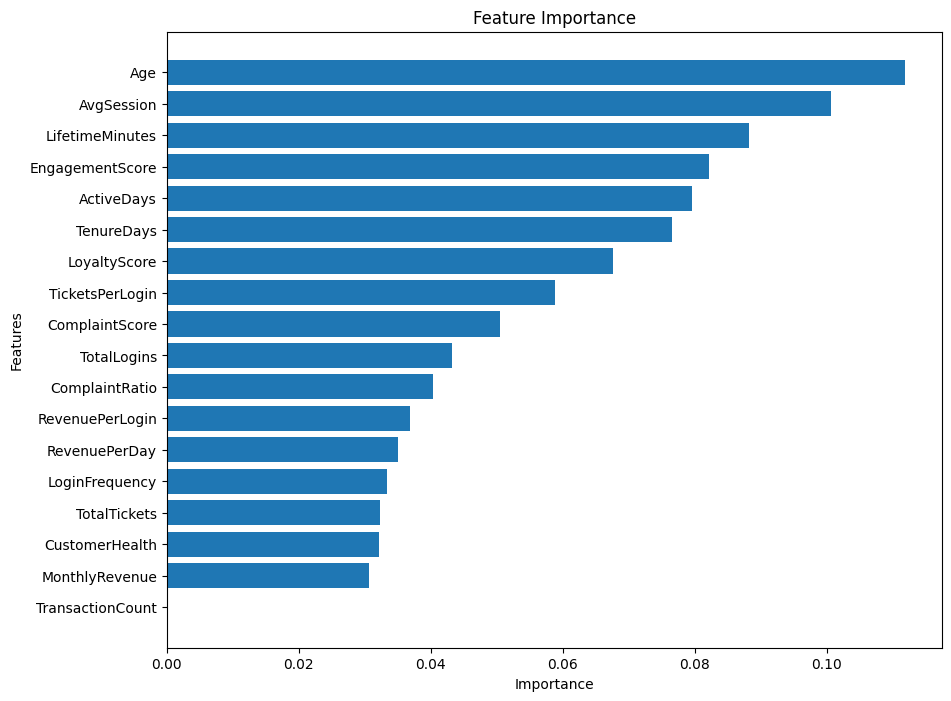

In [0]:
# Plot Feature Importance 
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

plt.barh(

feature_importance["Feature"],

feature_importance["Importance"]

)

plt.title("Feature Importance")

plt.xlabel("Importance")

plt.ylabel("Features")

plt.gca().invert_yaxis()

plt.show()

In [0]:
# Select Top Features 
top_features = feature_importance.head(15)

top_features

,Feature,Importance
0,Age,0.111847
6,AvgSession,0.100683
5,LifetimeMinutes,0.088280
15,EngagementScore,0.082120
7,ActiveDays,0.079527
1,TenureDays,0.076596
17,LoyaltyScore,0.067605
13,TicketsPerLogin,0.058898
10,ComplaintScore,0.050526
4,TotalLogins,0.043284


In [0]:
# Display Top Features 
display(top_features)

Feature,Importance
Age,0.11184747797753129
AvgSession,0.10068347388194562
LifetimeMinutes,0.08827985094107828
EngagementScore,0.08212021005196452
ActiveDays,0.07952721093269378
TenureDays,0.07659617950443157
LoyaltyScore,0.06760464124832942
TicketsPerLogin,0.05889807875817988
ComplaintScore,0.05052622185130418
TotalLogins,0.04328447371863107


In [0]:
# Create Final ML Dataset 
ml_dataset = gold.select(

"CustomerID",

"scaled_features",

"label"

)

display(ml_dataset.limit(10))

CustomerID,scaled_features,label
100030,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}",0.0
100036,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}",0.0
100042,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}",0.0
100043,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.5714469091134694"",""0.5017037789362383"",""-0.5912320345914457"",""0.0"",""-0.4484382496396012"",""-0.6976644474584527"",""-0.6542564223713676"",""-0.3646982166904183"",""-0.20528502621170325"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.6653263340107006"",""-0.35087869992540816"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.4510289960825741"",""-0.6070927175107699"",""0.5017037789362383""]}",0.0
100060,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6270066423868055"",""-1.4665176541698055"",""1.0250281728877428"",""0.0"",""0.008208379665322391"",""0.8888830904649767"",""1.546248748766258"",""0.9874235260366689"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""2.5985000807153225"",""0.21640979219593814"",""-0.5681575624813238"",""-0.34133703226515455"",""1.1890099280292505"",""1.0672193128192116"",""-1.4665176541698055""]}",0.0
100068,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-1.6367389548914917"",""1.466756013302494"",""-0.8527509579596336"",""0.0"",""2.2914415261899403"",""1.3709831710494442"",""-0.5136369209342481"",""1.1550866221348277"",""-0.1503473500039918"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.8805666851017455"",""-0.8428752177665033"",""-0.5681575624813238"",""-0.34133703226515455"",""1.0654836600434336"",""-0.8137314353419968"",""1.466756013302494""]}",0.0
100082,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.22752212522004717"",""1.1739484233421758"",""1.4361957983628575"",""0.0"",""-0.9050848789445248"",""-0.07093434269864496"",""2.075788853277212"",""-0.5864461824976607"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.09396103838720024"",""1.3791847327133782"",""-0.932904051073773"",""-1.4955190158535085"",""-0.28691324288537584"",""1.4248565960376829"",""1.1739484233421758""]}",0.0
100084,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.1596526652758166"",""-0.45122033040207515"",""-0.9400700699707565"",""0.0"",""-0.9050848789445248"",""-0.7371089995062727"",""0.1501884732373788"",""-0.34847275577769327"",""-0.20528502621170325"",""1.6868653977535484E-4"",""0.6257344151365856"",""-0.6105378810057075"",""-0.36569565216351324"",""0.28899668571093234"",""1.101390447220288"",""-0.3223890921646148"",""-0.951056312209025"",""-0.45122033040207515""]}",0.0
100135,"{""type"":""1"",""size"":null,""indices"":null,""values""

In [0]:
gold = spark.table("gold_feature_selected")

In [0]:
display(gold.limit(5))

CustomerID,JoinDate,Segment,Region,Age,SubscriptionType,TenureDays,AgeGroup,BillingMonth,MonthlyRevenue,TransactionCount,TotalLogins,LifetimeMinutes,AvgSession,LastLoginDate,FirstLoginDate,ActiveDays,LoginFrequency,UsageLevel,SessionCategory,RecentlyActive,TotalTickets,LastTicketDate,OpenTickets,ClosedTickets,ComplaintScore,SupportLevel,OpenTicketRatio,SupportRisk,Churn,ChurnStatus,RetentionFlag,RevenuePerLogin,TicketsPerLogin,EngagementScore,ComplaintRatio,RevenueCategory,LifetimeSegment,LoginCategory,UsageCategory,RiskScore,HighRiskCustomer,CustomerHealth,HealthCategory,LoyaltyScore,RevenuePerDay,Segment_Index,Region_Index,SubscriptionType_Index,RevenueCategory_Index,UsageCategory_Index,SupportRisk_Index,features,scaled_features
100030,2022-06-19,PREMIUM,INDIA,48,MONTHLY,1468,45-59,2024-06,2835.29,1.0,6.0,447.0,74.5,2025-07-16,2024-04-20,452,0.01,LOW,LONG,0,3,2024-07-22,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,472.55,0.5,175.5,2.0,SILVER,LOYAL,LOW,LIGHT,33.36,0,1505.4,EXCELLENT,734.5,1.93,1.0,0.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""48.0"",""1468.0"",""2835.29"",""1.0"",""6.0"",""447.0"",""74.5"",""452.0"",""0.01"",""3.0"",""6.0"",""1.93"",""472.55"",""0.5"",""2.0"",""175.5"",""1505.4"",""734.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}"
100036,2024-09-12,BASIC,USA,43,MONTHLY,652,35-44,2024-01,2912.39,1.0,7.0,682.0,97.42857142857143,2025-05-05,2024-03-16,415,0.02,LOW,LONG,0,3,2025-12-03,1,2,11.0,LOW,0.33,LOW,0,ACTIVE,1,416.06,0.43,170.82,3.67,SILVER,ESTABLISHED,LOW,LIGHT,35.49,0,1541.61,EXCELLENT,326.5,4.47,0.0,1.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""43.0"",""652.0"",""2912.39"",""1.0"",""7.0"",""682.0"",""97.42857142857143"",""415.0"",""0.02"",""3.0"",""11.0"",""4.47"",""416.06"",""0.43"",""3.67"",""170.82"",""1541.61"",""326.5""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}"
100042,2023-11-02,BASIC,UK,55,MONTHLY,967,45-59,2024-11,3319.43,1.0,8.0,865.0,108.125,2025-09-08,2024-02-16,570,0.01,LOW,LONG,0,3,2024-05-21,0,3,6.0,LOW,0.0,LOW,0,ACTIVE,1,414.93,0.38,226.05,2.0,SILVER,LOYAL,LOW,LIGHT,32.28,0,1772.74,EXCELLENT,484.0,3.43,0.0,2.0,0.0,0.0,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""55.0"",""967.0"",""3319.43"",""1.0"",""8.0"",""865.0"",""108.125"",""570.0"",""0.01"",""3.0"",""6.0"",""3.43"",""414.93"",""0.38"",""2.0"",""226.05"",""1772.74"",""484.0""]}","{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}"
100043,2021-12-10,BASIC,USA,35,MONTHLY,1659,35-44,2024-11,2278.93,1.0,4.0,290.0,72.5,2025-04-07,2024-03-26,377,0.01,LOW,LONG,0,2,2025-05-30,0,2,4.0,LOW,0.0,LOW,0,ACTIVE,1,569.73,0.5,149.84,2.0,SILVER,LOYAL,LOW,LIGHT,33.52,0,1214.39,EXCELLENT,830.0,1.37,0

In [0]:
ml_dataset = gold.select(
    "CustomerID",
    "scaled_features",
    "Churn"
)

display(ml_dataset.limit(10))

CustomerID,scaled_features,Churn
100030,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}",0
100036,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}",0
100042,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}",0
100043,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.5714469091134694"",""0.5017037789362383"",""-0.5912320345914457"",""0.0"",""-0.4484382496396012"",""-0.6976644474584527"",""-0.6542564223713676"",""-0.3646982166904183"",""-0.20528502621170325"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.6653263340107006"",""-0.35087869992540816"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.4510289960825741"",""-0.6070927175107699"",""0.5017037789362383""]}",0
100060,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6270066423868055"",""-1.4665176541698055"",""1.0250281728877428"",""0.0"",""0.008208379665322391"",""0.8888830904649767"",""1.546248748766258"",""0.9874235260366689"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""2.5985000807153225"",""0.21640979219593814"",""-0.5681575624813238"",""-0.34133703226515455"",""1.1890099280292505"",""1.0672193128192116"",""-1.4665176541698055""]}",0
100068,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-1.6367389548914917"",""1.466756013302494"",""-0.8527509579596336"",""0.0"",""2.2914415261899403"",""1.3709831710494442"",""-0.5136369209342481"",""1.1550866221348277"",""-0.1503473500039918"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.8805666851017455"",""-0.8428752177665033"",""-0.5681575624813238"",""-0.34133703226515455"",""1.0654836600434336"",""-0.8137314353419968"",""1.466756013302494""]}",0
100082,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.22752212522004717"",""1.1739484233421758"",""1.4361957983628575"",""0.0"",""-0.9050848789445248"",""-0.07093434269864496"",""2.075788853277212"",""-0.5864461824976607"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.09396103838720024"",""1.3791847327133782"",""-0.932904051073773"",""-1.4955190158535085"",""-0.28691324288537584"",""1.4248565960376829"",""1.1739484233421758""]}",0
100084,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.1596526652758166"",""-0.45122033040207515"",""-0.9400700699707565"",""0.0"",""-0.9050848789445248"",""-0.7371089995062727"",""0.1501884732373788"",""-0.34847275577769327"",""-0.20528502621170325"",""1.6868653977535484E-4"",""0.6257344151365856"",""-0.6105378810057075"",""-0.36569565216351324"",""0.28899668571093234"",""1.101390447220288"",""-0.3223890921646148"",""-0.951056312209025"",""-0.45122033040207515""]}",0
100135,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.0930719124

In [0]:
ml_dataset.write \
.mode("overwrite") \
.option("overwriteSchema","true") \
.saveAsTable("customer_churn_ml_dataset")

In [0]:
display(
    spark.table("customer_churn_ml_dataset").limit(10)
)

CustomerID,scaled_features,Churn
100030,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}",0
100036,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}",0
100042,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}",0
100043,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.5714469091134694"",""0.5017037789362383"",""-0.5912320345914457"",""0.0"",""-0.4484382496396012"",""-0.6976644474584527"",""-0.6542564223713676"",""-0.3646982166904183"",""-0.20528502621170325"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.6653263340107006"",""-0.35087869992540816"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.4510289960825741"",""-0.6070927175107699"",""0.5017037789362383""]}",0
100060,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6270066423868055"",""-1.4665176541698055"",""1.0250281728877428"",""0.0"",""0.008208379665322391"",""0.8888830904649767"",""1.546248748766258"",""0.9874235260366689"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""2.5985000807153225"",""0.21640979219593814"",""-0.5681575624813238"",""-0.34133703226515455"",""1.1890099280292505"",""1.0672193128192116"",""-1.4665176541698055""]}",0
100068,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-1.6367389548914917"",""1.466756013302494"",""-0.8527509579596336"",""0.0"",""2.2914415261899403"",""1.3709831710494442"",""-0.5136369209342481"",""1.1550866221348277"",""-0.1503473500039918"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.8805666851017455"",""-0.8428752177665033"",""-0.5681575624813238"",""-0.34133703226515455"",""1.0654836600434336"",""-0.8137314353419968"",""1.466756013302494""]}",0
100082,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.22752212522004717"",""1.1739484233421758"",""1.4361957983628575"",""0.0"",""-0.9050848789445248"",""-0.07093434269864496"",""2.075788853277212"",""-0.5864461824976607"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.09396103838720024"",""1.3791847327133782"",""-0.932904051073773"",""-1.4955190158535085"",""-0.28691324288537584"",""1.4248565960376829"",""1.1739484233421758""]}",0
100084,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.1596526652758166"",""-0.45122033040207515"",""-0.9400700699707565"",""0.0"",""-0.9050848789445248"",""-0.7371089995062727"",""0.1501884732373788"",""-0.34847275577769327"",""-0.20528502621170325"",""1.6868653977535484E-4"",""0.6257344151365856"",""-0.6105378810057075"",""-0.36569565216351324"",""0.28899668571093234"",""1.101390447220288"",""-0.3223890921646148"",""-0.951056312209025"",""-0.45122033040207515""]}",0
100135,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.0930719124

In [0]:
# Create Final ML Dataset 
# Create Final Machine Learning Dataset

ml_dataset = gold.select(
    "CustomerID",
    "scaled_features",
    "Churn"
)

display(ml_dataset.limit(10))

CustomerID,scaled_features,Churn
100030,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}",0
100036,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}",0
100042,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}",0
100043,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.5714469091134694"",""0.5017037789362383"",""-0.5912320345914457"",""0.0"",""-0.4484382496396012"",""-0.6976644474584527"",""-0.6542564223713676"",""-0.3646982166904183"",""-0.20528502621170325"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.6653263340107006"",""-0.35087869992540816"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.4510289960825741"",""-0.6070927175107699"",""0.5017037789362383""]}",0
100060,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6270066423868055"",""-1.4665176541698055"",""1.0250281728877428"",""0.0"",""0.008208379665322391"",""0.8888830904649767"",""1.546248748766258"",""0.9874235260366689"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""2.5985000807153225"",""0.21640979219593814"",""-0.5681575624813238"",""-0.34133703226515455"",""1.1890099280292505"",""1.0672193128192116"",""-1.4665176541698055""]}",0
100068,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-1.6367389548914917"",""1.466756013302494"",""-0.8527509579596336"",""0.0"",""2.2914415261899403"",""1.3709831710494442"",""-0.5136369209342481"",""1.1550866221348277"",""-0.1503473500039918"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.8805666851017455"",""-0.8428752177665033"",""-0.5681575624813238"",""-0.34133703226515455"",""1.0654836600434336"",""-0.8137314353419968"",""1.466756013302494""]}",0
100082,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.22752212522004717"",""1.1739484233421758"",""1.4361957983628575"",""0.0"",""-0.9050848789445248"",""-0.07093434269864496"",""2.075788853277212"",""-0.5864461824976607"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.09396103838720024"",""1.3791847327133782"",""-0.932904051073773"",""-1.4955190158535085"",""-0.28691324288537584"",""1.4248565960376829"",""1.1739484233421758""]}",0
100084,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.1596526652758166"",""-0.45122033040207515"",""-0.9400700699707565"",""0.0"",""-0.9050848789445248"",""-0.7371089995062727"",""0.1501884732373788"",""-0.34847275577769327"",""-0.20528502621170325"",""1.6868653977535484E-4"",""0.6257344151365856"",""-0.6105378810057075"",""-0.36569565216351324"",""0.28899668571093234"",""1.101390447220288"",""-0.3223890921646148"",""-0.951056312209025"",""-0.45122033040207515""]}",0
100135,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.0930719124

In [0]:
# Save Final ML Dataset 
# Save Final ML Dataset

ml_dataset.write \
    .mode("overwrite") \
    .option("overwriteSchema", "true") \
    .saveAsTable("customer_churn_ml_dataset")

In [0]:
# Verify Saved Dataset 
# Verify Saved Dataset

customer_ml = spark.table("customer_churn_ml_dataset")

print("Total Rows :", customer_ml.count())

print("Total Columns :", len(customer_ml.columns))

display(customer_ml.limit(10))

Total Rows : 286893
Total Columns : 3


CustomerID,scaled_features,Churn
100030,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.2941028780811736"",""0.17077922460238765"",""-0.270290889328128"",""0.0"",""0.464855008970246"",""-0.009576150624258187"",""-0.5782458810540058"",""0.04093830612770786"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""-0.446172521990728"",""-0.47437024525122784"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.04097931477389807"",""-0.2715800618389218"",""0.17077922460238765""]}",0
100036,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.03880088622445837"",""-1.2430136357977284"",""-0.22581507816305185"",""0.0"",""0.9215016382751696"",""1.020364930624377"",""0.2931606819057498"",""-0.15917571179590106"",""-0.1503473500039918"",""0.7118596784530631"",""1.0352478719158427"",""0.5478465539570057"",""-0.5461549478181712"",""-0.148699100600007"",""0.622404924031121"",""-0.11576624028148212"",""-0.229832653633439"",""-1.2430136357977284""]}",0
100042,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7601681481090583"",""-0.6972480095403306"",""0.008989515567591628"",""0.0"",""1.3781482675800931"",""1.8224041555967183"",""0.6996813448441402"",""0.679139768694893"",""-0.20528502621170325"",""0.7118596784530631"",""0.011464229967700048"",""0.14084661734848491"",""-0.5475908960196343"",""-0.2398857227481193"",""-0.34133703226515455"",""0.7668153613817363"",""0.036642863034147294"",""-0.6972480095403306""]}",0
100043,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-0.5714469091134694"",""0.5017037789362383"",""-0.5912320345914457"",""0.0"",""-0.4484382496396012"",""-0.6976644474584527"",""-0.6542564223713676"",""-0.3646982166904183"",""-0.20528502621170325"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.6653263340107006"",""-0.35087869992540816"",""-0.021037829592649708"",""-0.34133703226515455"",""-0.4510289960825741"",""-0.6070927175107699"",""0.5017037789362383""]}",0
100060,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6270066423868055"",""-1.4665176541698055"",""1.0250281728877428"",""0.0"",""0.008208379665322391"",""0.8888830904649767"",""1.546248748766258"",""0.9874235260366689"",""-0.20528502621170325"",""-0.7115223053735125"",""-0.8075626835908141"",""2.5985000807153225"",""0.21640979219593814"",""-0.5681575624813238"",""-0.34133703226515455"",""1.1890099280292505"",""1.0672193128192116"",""-1.4665176541698055""]}",0
100068,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-1.6367389548914917"",""1.466756013302494"",""-0.8527509579596336"",""0.0"",""2.2914415261899403"",""1.3709831710494442"",""-0.5136369209342481"",""1.1550866221348277"",""-0.1503473500039918"",""1.6868653977535484E-4"",""-0.398049226811557"",""-0.8805666851017455"",""-0.8428752177665033"",""-0.5681575624813238"",""-0.34133703226515455"",""1.0654836600434336"",""-0.8137314353419968"",""1.466756013302494""]}",0
100082,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.22752212522004717"",""1.1739484233421758"",""1.4361957983628575"",""0.0"",""-0.9050848789445248"",""-0.07093434269864496"",""2.075788853277212"",""-0.5864461824976607"",""-0.20528502621170325"",""-1.4232132972868001"",""-1.2170761403700712"",""-0.09396103838720024"",""1.3791847327133782"",""-0.932904051073773"",""-1.4955190158535085"",""-0.28691324288537584"",""1.4248565960376829"",""1.1739484233421758""]}",0
100084,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.1596526652758166"",""-0.45122033040207515"",""-0.9400700699707565"",""0.0"",""-0.9050848789445248"",""-0.7371089995062727"",""0.1501884732373788"",""-0.34847275577769327"",""-0.20528502621170325"",""1.6868653977535484E-4"",""0.6257344151365856"",""-0.6105378810057075"",""-0.36569565216351324"",""0.28899668571093234"",""1.101390447220288"",""-0.3223890921646148"",""-0.951056312209025"",""-0.45122033040207515""]}",0
100135,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""1.0930719124

In [0]:
#Notebook 13 Summary

# The Feature Engineering process has been completed successfully.

# Operations Performed

# • Exploratory Data Analysis (EDA)
# • Missing Value Analysis
# • Outlier Detection
# • Outlier Treatment (IQR Capping)
# • Business Feature Engineering
# • Categorical Encoding
# • Feature Scaling
# • Correlation Analysis
# • Feature Selection
# • Created Final Machine Learning Dataset

# Output Table

# customer_churn_ml_dataset

In [0]:
# "Notebook 13 prepares the Gold Layer dataset for Machine Learning. It performs exploratory data analysis, data cleaning, feature engineering, encoding, scaling, and feature selection. The final output is the customer_churn_ml_dataset table, which contains the customer identifier, engineered feature vector (scaled_features), and the target variable (Churn). This dataset serves as the input for model training in the next notebook."